# Learning a Graph from a Year of New England Temperatures

Lesson 3 built graphs from **coordinates** — $k$-nearest-neighbour and Delaunay — and found that
they explained a single day's temperature field only weakly: a two-parameter regression on station
elevation matched what took six to nine graph modes, and the answer depended heavily on which
construction was chosen.

That leaves an obvious question. We were guessing the edges from geography. **What if we learned
them from the data instead?** Three years of daily observations give 1096 samples of the same
85-node signal, which is exactly the setting graph-learning methods were designed for.

**The question this notebook answers:** *does learning connections from repeated observations
improve graph representation and missing-value reconstruction, compared with geographic graphs —
and does any improvement survive on days that were not used to learn the graph?*

**Audience.** You know Laplacians, the GFT, spectral energy, and filtering. Graph *learning* is new.

**Scope.** Fixed, undirected, **weighted** graphs — Lesson 3's unweighted restriction is lifted here,
because every learning method produces real-valued weights. Days are treated as repeated,
exchangeable observations of one node signal. No temporal graph and no neural network.

### The seven constructions

| | Method | Edges come from | Learns weights? |
|---|---|---|---|
| **A** | Geographic ($k$-NN, Gaussian kernel) | coordinates only | no / by formula |
| **B** | Measurement similarity (Gaussian, correlation) | training temperatures, by formula | by formula |
| **C** | **Kalofolias** (AISTATS 2016) | convex optimisation | yes |
| **D** | **GL-SigRep** (Dong et al. 2016) | alternating optimisation | yes |
| **E** | **IGL-3SR** (Humbert et al. 2021) | manifold optimisation | yes |
| **F** | **FGL-3SR** (Humbert et al. 2021) | relaxed alternating optimisation | yes |
| **G** | **ESA-GL** (Sardellitti et al. 2019) | transform learning + SDP | yes |

### Roadmap

1. A year of data, its quality flags, and a documented station set
2. A fair experiment: season-balanced splits, what each model sees, and the common scale
3. Every method — objective, update steps, parameters, resulting graph, strengths and weaknesses
4. Comparison on days no method ever saw
5. Verdict, verification, and the comparison table

> **Solver helpers live in [`glearn.py`](glearn.py).** Objectives and update steps are shown in this
> notebook; only the plumbing is hidden. One design decision there is load-bearing enough to state
> up front: every learner returns a vector $w \ge 0$ of **edge weights** on the upper triangle, and
> $L$ is assembled as $\operatorname{diag}(W\mathbf{1}) - W$. Laplacian validity is therefore
> *structural*, not a constraint the solver has to satisfy — nothing is ever repaired after the
> fact. Section 2 shows why that also matters numerically.


In [1]:
import os, io, json, time, zipfile, urllib.request, urllib.parse, socket, hashlib
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import scipy.sparse as sp
from pyproj import Transformer, CRS

import glearn as gl

SEED = 7
rng = np.random.default_rng(SEED)
socket.setdefaulttimeout(300)

plt.rcParams.update({
    "figure.dpi": 110, "figure.constrained_layout.use": True,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
})
C_LINE, C_RED, C_GREEN, C_ORANGE = "#2b6cb0", "#c53030", "#2f855a", "#e07a3f"
DATA_DIR = "data"; CACHE_DIR = os.path.join(DATA_DIR, "fits")
os.makedirs(CACHE_DIR, exist_ok=True)

import scipy, matplotlib, cvxpy, pymanopt, pyproj, shapefile
for nm, mod in [("numpy", np), ("scipy", scipy), ("pandas", pd), ("networkx", nx),
                ("matplotlib", matplotlib), ("pyproj", pyproj), ("cvxpy", cvxpy),
                ("pymanopt", pymanopt), ("pyshp", shapefile)]:
    print(f"{nm:<12} {mod.__version__}")
print(f"\ncvxpy solvers: {cvxpy.installed_solvers()}")

numpy        2.5.3
scipy        1.18.1
pandas       3.0.5
networkx     3.6.1
matplotlib   3.11.1
pyproj       3.8.0
cvxpy        1.9.2
pymanopt     2.2.1
pyshp        3.1.6

cvxpy solvers: ['CLARABEL', 'SCS', 'SCIPY', 'HIGHS', 'OSQP']


---
## 1. A year of data

**The years.** Lesson 3's example date was 2015-08-06, so we start from the calendar year
containing it and take three: **2015-2017**, or 1096 days. `YEARS` below is configurable and the
whole notebook follows it. Three years rather than one matters for a reason specific to graph
learning: every method here estimates $O(N^2)$ edge parameters from $T$ observations, so tripling
$T$ moves the estimation problem meaningfully away from the regime where the fit is dominated by
sampling noise.

**The stations.** We start from the exact 97 stations Lesson 3 ended with (US stations in CT/RI/MA
carrying a valid `TMAX` on 2015-08-06, after its de-duplication rule) and ask which of them report
through the year.

**The quality flags matter more here than they did in Lesson 3.** On a single day nothing failed
quality control, so the `QFLAG` filter was a no-op and the notebook said so. Over a full year that
is no longer true — flagged values do appear, and they look perfectly ordinary in a plot.


In [2]:
YEARS = (2015, 2016, 2017)                 # 2016 is a leap year: 365 + 366 + 365 = 1096 days
ACCESS_BASE = "https://www.ncei.noaa.gov/access/services/data/v1"
DAY0_CACHE = os.path.join(DATA_DIR, "ghcn_tmax_ct_ri_ma_2015-08-06.csv")
YEAR_CACHE = os.path.join(DATA_DIR, f"ghcn_tmax_ct_ri_ma_{YEARS[0]}_{YEARS[-1]}.csv")

def lesson3_stations():
    """The 97 stations Lesson 3 finished with: valid TMAX on its example date,
    de-duplicated by keeping the first station ID among coincident coordinates."""
    raw = pd.read_csv(DAY0_CACHE, dtype=str)
    at = raw["TMAX_ATTRIBUTES"].fillna("").str.split(",")
    raw["qflag"] = at.str[1].fillna("")
    raw["val"] = pd.to_numeric(raw["TMAX"], errors="coerce")
    ok = raw["val"].notna() & (raw["val"] != -9999) & (raw["qflag"] == "")
    sel = raw.loc[ok].copy()
    for c in ("LATITUDE", "LONGITUDE", "ELEVATION"):
        sel[c] = pd.to_numeric(sel[c])
    sel = (sel.sort_values("STATION")
              .drop_duplicates(subset=["LATITUDE", "LONGITUDE"], keep="first")
              .reset_index(drop=True))
    return sel.rename(columns={"STATION": "station", "LATITUDE": "lat",
                               "LONGITUDE": "lon", "ELEVATION": "elev_m"})[
        ["station", "lat", "lon", "elev_m"]]

meta0 = lesson3_stations()
print(f"stations inherited from Lesson 3: {len(meta0)}")

if os.path.exists(YEAR_CACHE):
    raw_year = pd.read_csv(YEAR_CACHE, dtype=str)
    print(f"loaded cache: {YEAR_CACHE}")
else:
    ids = meta0["station"].tolist()
    frames = []
    for s in range(0, len(ids), 100):            # the service allows 100 stations per call
        url = (f"{ACCESS_BASE}?dataset=daily-summaries&dataTypes=TMAX"
               f"&stations={','.join(ids[s:s+100])}"
               f"&startDate={YEARS[0]}-01-01&endDate={YEARS[-1]}-12-31"
               f"&format=csv&includeStationLocation=true&includeAttributes=true")
        with urllib.request.urlopen(url) as r:
            frames.append(pd.read_csv(io.StringIO(r.read().decode()), dtype=str))
    raw_year = pd.concat(frames, ignore_index=True)
    raw_year.to_csv(YEAR_CACHE, index=False)
    print(f"downloaded and cached {len(raw_year)} rows -> {YEAR_CACHE}")

n_days_total = (pd.Timestamp(f"{YEARS[-1]}-12-31") - pd.Timestamp(f"{YEARS[0]}-01-01")).days + 1
print(f"rows: {len(raw_year)}   (97 stations x {n_days_total} days would be {97*n_days_total})")

stations inherited from Lesson 3: 97
loaded cache: data\ghcn_tmax_ct_ri_ma_2015_2017.csv
rows: 102621   (97 stations x 1096 days would be 106312)


In [3]:
# --- quality control, exactly as documented in the GHCN-Daily readme ----------
obs = raw_year.copy()
at = obs["TMAX_ATTRIBUTES"].fillna("").str.split(",")
obs["mflag"], obs["qflag"], obs["sflag"] = at.str[0].fillna(""), at.str[1].fillna(""), at.str[2].fillna("")
obs["raw"] = pd.to_numeric(obs["TMAX"], errors="coerce")

present  = obs["raw"].notna()
notmiss  = present & (obs["raw"] != -9999)
passedqc = notmiss & (obs["qflag"] == "")

print(f"rows returned                        : {len(obs)}")
print(f"  value present                      : {int(present.sum()):6d}  (dropped {int((~present).sum())})")
print(f"  not the -9999 sentinel             : {int(notmiss.sum()):6d}  (dropped {int((present & ~notmiss).sum())})")
print(f"  blank QFLAG (passed quality checks) : {int(passedqc.sum()):6d}  (dropped {int((notmiss & ~passedqc).sum())})")
print()
flagged = obs.loc[notmiss & ~passedqc, "qflag"].value_counts()
print("QFLAG values that DID occur this year:")
for f, c in flagged.items():
    meaning = {"I": "failed internal consistency check",
               "S": "failed spatial consistency check",
               "G": "failed gap check", "X": "failed bounds check"}.get(f, "see readme section VII")
    print(f"   '{f}' : {c:4d} observations   ({meaning})")
print("\nLesson 3 saw none of these on its single date. Over a year they are real, and a")
print("spatially-inconsistent TMAX is exactly the kind of value that would look fine on a map.")

obs = obs.loc[passedqc].copy()
obs["tmax_c"] = obs["raw"] / 10.0            # tenths of degC -> degC

rows returned                        : 102621
  value present                      : 100367  (dropped 2254)
  not the -9999 sentinel             : 100367  (dropped 0)
  blank QFLAG (passed quality checks) : 100339  (dropped 28)

QFLAG values that DID occur this year:
   'I' :   21 observations   (failed internal consistency check)
   'S' :    7 observations   (failed spatial consistency check)

Lesson 3 saw none of these on its single date. Over a year they are real, and a
spatially-inconsistent TMAX is exactly the kind of value that would look fine on a map.


In [4]:
# --- the station x day matrix -------------------------------------------------
all_days = pd.date_range(f"{YEARS[0]}-01-01", f"{YEARS[-1]}-12-31").strftime("%Y-%m-%d")
Ywide = (obs.pivot_table(index="STATION", columns="DATE", values="tmax_c", aggfunc="first")
            .reindex(columns=all_days))
coverage = Ywide.notna().mean(axis=1)

print(f"{'availability rule':>28s}{'stations N':>12s}{'fully observed days':>22s}")
for thr in [0.80, 0.85, 0.90, 0.95, 0.98]:
    s = Ywide.loc[coverage >= thr]
    print(f"{'coverage >= ' + format(thr, '.0%'):>28s}{s.shape[0]:12d}"
          f"{int(s.notna().all(axis=0).sum()):22d}")

COVERAGE_RULE = 0.90
keep_ids = coverage.index[coverage >= COVERAGE_RULE]
Ywide = Ywide.loc[sorted(keep_ids)]
meta = (meta0.set_index("station").reindex(Ywide.index)
            .rename_axis("station").reset_index())

station_ids = Ywide.index.tolist()
N = len(station_ids)
dates = pd.to_datetime(Ywide.columns)
Y = Ywide.to_numpy(float)                      # (N, 1096), NaN where missing
observed = ~np.isnan(Y)
complete_day = observed.all(axis=0)

print(f"\nRULE: keep stations reporting on at least {COVERAGE_RULE:.0%} of days.")
print(f"  N = {N} stations (Lesson 3 had {len(meta0)}; {len(meta0)-N} dropped for sparse reporting)")
print(f"  Y is {Y.shape},  missing entries {int((~observed).sum())} "
      f"({100*(~observed).mean():.3f}%)")
print(f"  fully observed days: {int(complete_day.sum())} of {len(all_days)}")
print(f"  TMAX range {np.nanmin(Y):.1f} .. {np.nanmax(Y):.1f} degC")

           availability rule  stations N   fully observed days
             coverage >= 80%          90                   314
             coverage >= 85%          89                   388
             coverage >= 90%          85                   600
             coverage >= 95%          83                   703
             coverage >= 98%          77                   836

RULE: keep stations reporting on at least 90% of days.
  N = 85 stations (Lesson 3 had 97; 12 dropped for sparse reporting)
  Y is (85, 1096),  missing entries 687 (0.737%)
  fully observed days: 600 of 1096
  TMAX range -17.2 .. 37.8 degC


In [5]:
# --- projected coordinates, same CRS as Lesson 3 ------------------------------
CRS_PROJECTED = "EPSG:26986"     # NAD83 / Massachusetts Mainland, metres
to_metric = Transformer.from_crs("EPSG:4326", CRS_PROJECTED, always_xy=True)
ee, nn = to_metric.transform(meta["lon"].to_numpy(), meta["lat"].to_numpy())
P = np.column_stack([ee, nn])                       # positions p_i, metres
elev = meta["elev_m"].to_numpy()
Dphys2 = ((P[:, None, :] - P[None, :, :]) ** 2).sum(-1)     # squared distance, m^2
print(f"CRS: {CRS.from_user_input(CRS_PROJECTED).name}")
print(f"positions {P.shape}; separation {np.sqrt(Dphys2[Dphys2>0]).min()/1000:.1f}"
      f" .. {np.sqrt(Dphys2).max()/1000:.0f} km")

ei = gl.EdgeIndex(N)          # upper-triangle edge bookkeeping, m = N(N-1)/2
print(f"edge slots m = {ei.m}")

# --- state borders for the maps ----------------------------------------------
# Two Census products look interchangeable and are not:
#   * TIGER/Line and the TIGERweb "State" layers give the LEGAL boundary, which
#     extends roughly three nautical miles offshore into state waters. Drawn, it
#     turns Cape Cod into a blob, fills in Narragansett and Buzzards Bay, and
#     makes a station standing on the shore plot well inland.
#   * The CARTOGRAPHIC BOUNDARY files (cb_*) are clipped to the shoreline, which
#     is what a reader means by "the outline of the state".
# We use cb_2023_us_state_500k -- 1:500,000, the most detailed cartographic
# boundary Census publishes -- filtered to CT (09), MA (25) and RI (44). State
# outlines only: no counties, roads, or hydrography.
STATE_FIPS = {"09": "Connecticut", "25": "Massachusetts", "44": "Rhode Island"}
CB_BASE = "cb_2023_us_state_500k"
CB_URL = f"https://www2.census.gov/geo/tiger/GENZ2023/shp/{CB_BASE}.zip"
CB_CACHE = os.path.join(DATA_DIR, f"{CB_BASE}.zip")

if not os.path.exists(CB_CACHE):
    print(f"downloading {CB_URL} (3.3 MB, once) ...")
    urllib.request.urlretrieve(CB_URL, CB_CACHE)

def load_state_rings():
    """Shoreline-clipped boundary rings in the same projected km coordinates as
    the stations. Each record holds several PARTS -- mainland plus every island --
    which must be drawn separately, or the pen strikes a line between islands."""
    zf = zipfile.ZipFile(CB_CACHE)
    sf = shapefile.Reader(shp=io.BytesIO(zf.read(CB_BASE + ".shp")),
                          dbf=io.BytesIO(zf.read(CB_BASE + ".dbf")),
                          shx=io.BytesIO(zf.read(CB_BASE + ".shx")))
    fields = [f[0] for f in sf.fields[1:]]
    rings = []
    for rec, shp in zip(sf.records(), sf.shapes()):
        if dict(zip(fields, rec)).get("STATEFP") not in STATE_FIPS:
            continue
        pts = np.asarray(shp.points, float)
        bounds = list(shp.parts) + [len(pts)]
        for a_, b_ in zip(bounds[:-1], bounds[1:]):
            seg = pts[a_:b_]
            e_, n_ = to_metric.transform(seg[:, 0], seg[:, 1])
            rings.append(np.column_stack([e_, n_]) / 1000.0)
    return rings

STATE_RINGS = load_state_rings()

def draw_states(ax, color="0.45", lw=0.6, zorder=0, alpha=0.9):
    """Draw CT / MA / RI shorelines and borders. Call before plotting stations."""
    for ring in STATE_RINGS:
        ax.plot(ring[:, 0], ring[:, 1], color=color, lw=lw, zorder=zorder,
                alpha=alpha, solid_joinstyle="round")

print(f"state outlines: {len(STATE_RINGS)} parts (mainland + every island), "
      f"{sum(len(r) for r in STATE_RINGS)} vertices, clipped to the shoreline")

CRS: NAD83 / Massachusetts Mainland
positions (85, 2); separation 0.2 .. 309 km
edge slots m = 3570


state outlines: 59 parts (mainland + every island), 5149 vertices, clipped to the shoreline


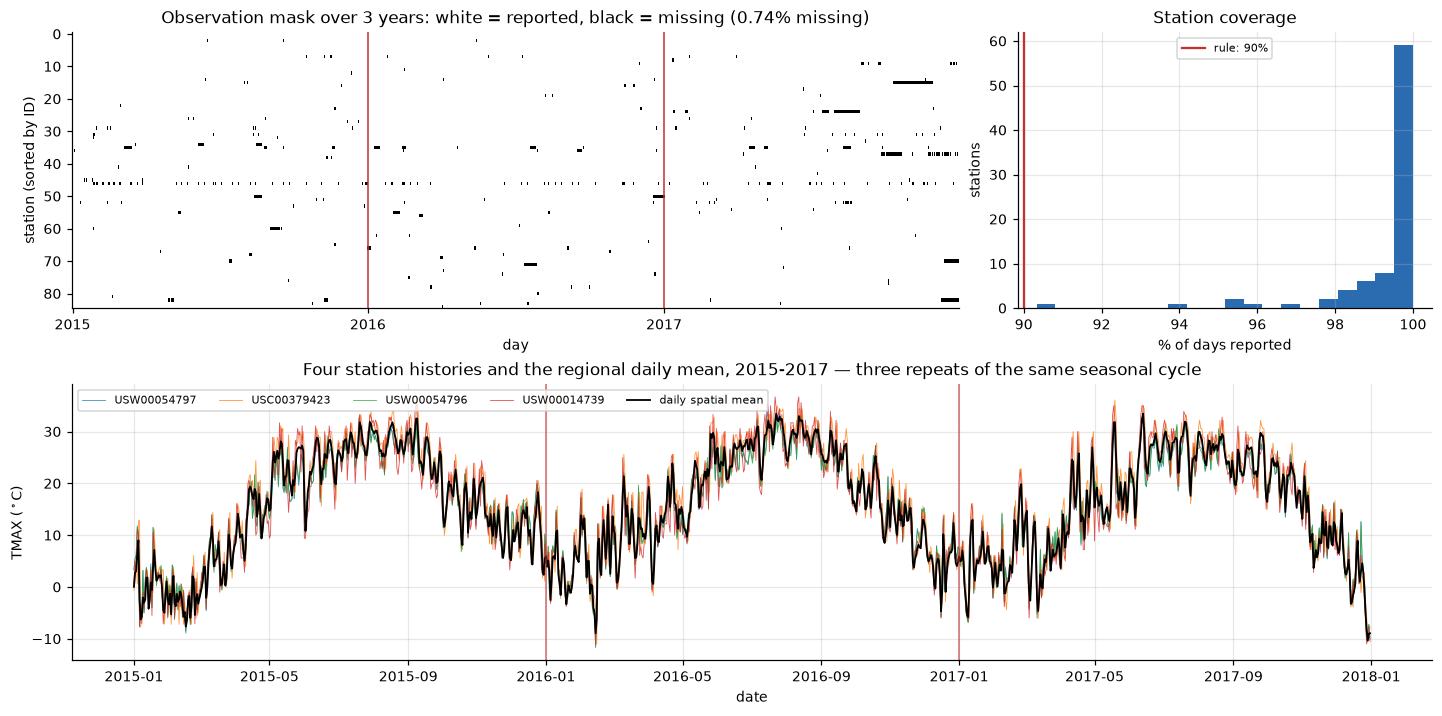

In [6]:
fig = plt.figure(figsize=(13, 6.4))
gs = fig.add_gridspec(2, 3)

year_starts = [list(all_days).index(f"{y}-01-01") for y in YEARS]

ax = fig.add_subplot(gs[0, :2])
im = ax.imshow(observed, aspect="auto", cmap="Greys_r", interpolation="nearest")
for b in year_starts[1:]:
    ax.axvline(b, color=C_RED, lw=1.0)
ax.set_xticks(year_starts); ax.set_xticklabels([str(y) for y in YEARS])
ax.set_xlabel("day"); ax.set_ylabel("station (sorted by ID)")
ax.set_title(f"Observation mask over {len(YEARS)} years: white = reported, black = missing "
             f"({100*(~observed).mean():.2f}% missing)")
ax.grid(False)

ax = fig.add_subplot(gs[0, 2])
ax.hist(coverage.loc[station_ids].to_numpy() * 100, bins=20, color=C_LINE)
ax.axvline(COVERAGE_RULE * 100, color=C_RED, lw=1.5, label=f"rule: {COVERAGE_RULE:.0%}")
ax.set_xlabel("% of days reported"); ax.set_ylabel("stations")
ax.set_title("Station coverage"); ax.legend(fontsize=7.5)

ax = fig.add_subplot(gs[1, :])
show = rng.choice(N, 4, replace=False)
for i in show:
    ax.plot(dates, Y[i], lw=0.55, alpha=0.8, label=f"{station_ids[i]}")
ax.plot(dates, np.nanmean(Y, axis=0), lw=1.2, color="black", label="daily spatial mean")
for y in YEARS[1:]:
    ax.axvline(pd.Timestamp(f"{y}-01-01"), color=C_RED, lw=1.0, alpha=0.7)
ax.set_ylabel("TMAX ($^\\circ$C)"); ax.set_xlabel("date")
ax.set_title(f"Four station histories and the regional daily mean, {YEARS[0]}-{YEARS[-1]} — "
             "three repeats of the same seasonal cycle")
ax.legend(fontsize=7.5, ncol=5)
plt.show()

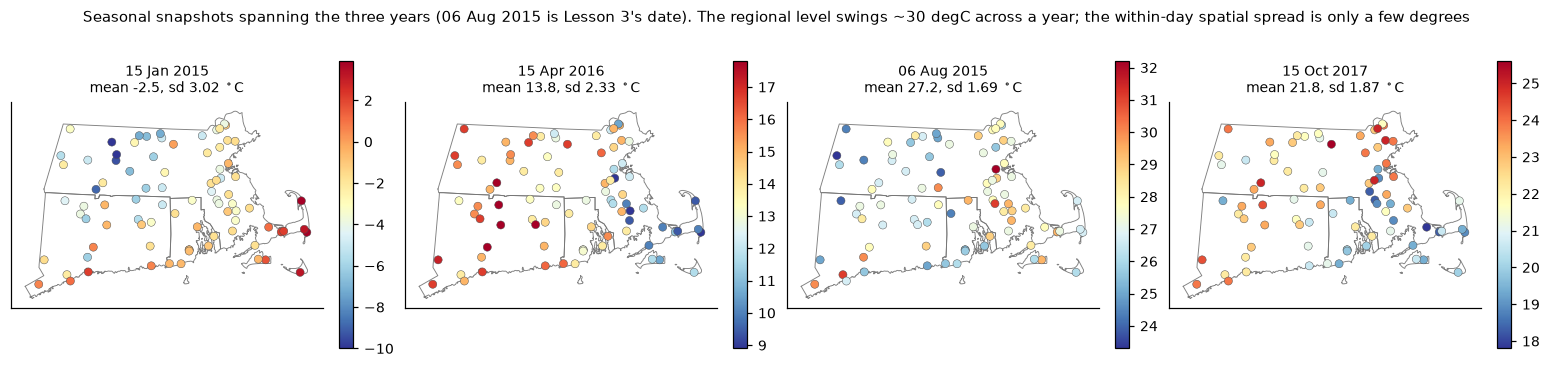

days: 1096 across 3 years (2015-2017)
daily regional mean :  -10.3 ..  33.5 degC (sd across days 10.23)
within-day spatial sd:   0.91 ..  6.72 degC (mean 2.56)

-> The seasonal cycle is ~10x the spatial structure. Any method that does not
   remove it will simply learn 'all stations are warm in July', which is true and
   useless. Section 2 fixes the representation before anything is learned.


In [7]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
SNAPSHOTS = [("15 Jan 2015", "2015-01-15"), ("15 Apr 2016", "2016-04-15"),
             ("06 Aug 2015", "2015-08-06"), ("15 Oct 2017", "2017-10-15")]
for ax, (label, day) in zip(axes, SNAPSHOTS):
    j = list(Ywide.columns).index(day)
    v = Y[:, j]
    draw_states(ax)                      # state borders only, drawn underneath
    sc = ax.scatter(P[:, 0] / 1000, P[:, 1] / 1000, c=v, cmap="RdYlBu_r", s=28,
                    edgecolor="0.3", linewidth=0.3, zorder=3)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"{label}\nmean {np.nanmean(v):.1f}, sd {np.nanstd(v):.2f} $^\\circ$C",
                 fontsize=9)
    fig.colorbar(sc, ax=ax, fraction=0.046)
fig.suptitle("Seasonal snapshots spanning the three years (06 Aug 2015 is Lesson 3's date). "
             "The regional level swings ~30 degC across a year; the within-day spatial "
             "spread is only a few degrees", fontsize=10)
plt.show()

sd_day = np.nanstd(Y, axis=0)
mean_day = np.nanmean(Y, axis=0)
print(f"days: {len(all_days)} across {len(YEARS)} years ({YEARS[0]}-{YEARS[-1]})")
print(f"daily regional mean : {mean_day.min():6.1f} .. {mean_day.max():5.1f} degC "
      f"(sd across days {mean_day.std():.2f})")
print(f"within-day spatial sd: {sd_day.min():6.2f} .. {sd_day.max():5.2f} degC "
      f"(mean {sd_day.mean():.2f})")
print("\n-> The seasonal cycle is ~10x the spatial structure. Any method that does not")
print("   remove it will simply learn 'all stations are warm in July', which is true and")
print("   useless. Section 2 fixes the representation before anything is learned.")

---
## 2. A fair experiment

Graph learning makes it very easy to fool yourself. The graph is fitted to data; if the same data is
then used to judge it, the fit is guaranteed to look good. Three separate precautions are needed,
and we set all of them up **before** any method runs.

### 2.1 What signal is each model given?

Every method in Section 3 receives the same matrix. From the raw $Y \in \mathbb{R}^{N\times T}$ we
remove, **per day**, the spatial mean over the stations visible that day:

$$z_t \;=\; y_t - \bar{y}_t\,\mathbf{1}, \qquad \bar{y}_t=\frac{1}{|O_t|}\sum_{i\in O_t} y_{it},$$

where $O_t$ is the set of stations reporting on day $t$. This is the **daily anomaly field**, and it
is the representation every model learns from and is scored on. Two reasons:

- It removes the seasonal cycle and the regional daily level in one step. Those are shared by all
  stations, so they say nothing about *connections* — and being ~10x larger than the spatial
  structure, they would otherwise dominate every objective.
- It makes each column orthogonal to $\mathbf{1}$, i.e. to the constant eigenvector, so the constant
  mode carries no energy and spectral comparisons are about structure only.

The centring quantity $\bar{y}_t$ is computed **within each day from visible stations only** — never
using the held-out stations we are about to try to reconstruct.

### 2.2 Splitting days

Adjacent days are strongly correlated, so a random day-wise split leaks. We use **season-balanced
blocks with gaps**: a repeating 14-day cycle of

$$\underbrace{6\ \text{train}}_{}\;\underbrace{1\ \text{gap}}_{}\;\underbrace{3\ \text{val}}_{}\;\underbrace{1\ \text{gap}}_{}\;\underbrace{3\ \text{test}}_{}\;\underbrace{1\ \text{gap}}_{}$$

repeated through all 1096 days. Every month of every year contributes to all three sets, so no
split is a different
season from another, and every block is isolated by a discarded gap day on **both** sides — the
trailing gap matters, since without it each cycle's test block would abut the next cycle's training
block and the whole precaution would be void at every wrap-around.

> ⚠️ **This measures reconstruction, not forecasting.** Training days come from throughout the year,
> including days *after* test days. That is the right design for the question "does this graph
> represent the spatial field well", and the wrong design for "can this predict tomorrow". Nothing
> here supports a forecasting claim.

### 2.3 What is fitted where

| Quantity | Fitted on | Selected on | Reported on |
|---|---|---|---|
| Edge weights $w$ (all methods) | train | — | — |
| Kernel bandwidths, $\alpha$, $\beta$, $K$ | train | **validation** | — |
| Reconstruction regulariser $\gamma$ | — | **validation** | — |
| PCA components | train | — | — |
| Everything in Section 4 | — | — | **test** |

Test days are touched exactly once, after every choice is frozen.


In [8]:
# --- 2.1 the signal representation -------------------------------------------
def daily_center(Ymat, mask):
    """Subtract, per day, the mean over the stations visible that day."""
    Z = np.array(Ymat, float)
    lvl = np.full(Ymat.shape[1], np.nan)
    for t in range(Ymat.shape[1]):
        o = mask[:, t]
        if o.any():
            lvl[t] = Ymat[o, t].mean()
            Z[:, t] = Ymat[:, t] - lvl[t]
    return Z, lvl

Zfull, day_level = daily_center(Y, observed)
print(f"daily anomaly field: sd {np.nanstd(Zfull):.2f} degC "
      f"(raw field sd was {np.nanstd(Y):.2f})")
print(f"every complete column sums to ~0: max |col sum| = "
      f"{np.nanmax(np.abs(np.nansum(Zfull[:, complete_day], axis=0))):.2e}")

daily anomaly field: sd 2.73 degC (raw field sd was 10.58)
every complete column sums to ~0: max |col sum| = 9.13e-13


In [9]:
# --- 2.2 season-balanced blocked split ----------------------------------------
CYCLE = [("train", 6), ("gap", 1), ("val", 3), ("gap", 1), ("test", 3), ("gap", 1)]
CYCLE_LEN = sum(n for _, n in CYCLE)
labels = np.empty(len(all_days), dtype=object)
pos = 0
while pos < len(all_days):
    for name, ln in CYCLE:
        end = min(pos + ln, len(all_days))
        labels[pos:end] = name
        pos = end
        if pos >= len(all_days):
            break

is_train = labels == "train"
is_val   = labels == "val"
is_test  = labels == "test"
is_gap   = labels == "gap"

# Evaluation uses fully observed days only, so nothing imputed is ever scored.
val_days  = np.where(is_val  & complete_day)[0]
test_days = np.where(is_test & complete_day)[0]
train_days = np.where(is_train)[0]                 # training may use partial days

print(f"{'split':8s}{'days':>7s}{'complete':>10s}{'used for':>34s}")
for nm, msk, used in [("train", is_train, "fitting graph weights"),
                      ("val", is_val, "hyperparameter selection (complete only)"),
                      ("test", is_test, "final report (complete only)"),
                      ("gap", is_gap, "discarded, prevents adjacency leakage")]:
    print(f"{nm:8s}{int(msk.sum()):7d}{int((msk & complete_day).sum()):10d}{used:>34s}")
print()
tab = pd.crosstab(pd.Series(dates.month), pd.Series(labels))[["train", "val", "test", "gap"]]
print("days per calendar month by split, pooled over the three years (season balance):")
print(tab.T.to_string())
tab_y = pd.crosstab(pd.Series(dates.year), pd.Series(labels))[["train", "val", "test", "gap"]]
print("\ndays per year by split:")
print(tab_y.T.to_string())

split      days  complete                          used for
train       439       246             fitting graph weights
val         219       118hyperparameter selection (complete only)
test        219       116      final report (complete only)
gap         219       120discarded, prevents adjacency leakage

days per calendar month by split, pooled over the three years (season balance):
row_0  1   2   3   4   5   6   7   8   9   10  11  12
col_0                                                
train  38  34  37  36  37  36  37  37  36  37  36  38
val    18  18  18  18  18  18  19  19  18  19  18  18
test   19  17  18  18  19  18  19  19  18  18  18  18
gap    18  16  20  18  19  18  18  18  18  19  18  19

days per year by split:
row_0  2015  2016  2017
col_0                  
train   149   145   145
val      72    75    72
test     72    72    75
gap      72    74    73


In [10]:
# --- training matrix: impute the few missing training entries, but ONLY there ---
# Rule: a missing training entry becomes that station's training-period anomaly mean
# (which is 0 by construction for fully observed stations, and the station's own bias
# otherwise). Imputed values are used to FIT graphs and are never scored.
Ztr_raw = Zfull[:, train_days]
tr_mask = observed[:, train_days]
station_bias = np.array([Ztr_raw[i, tr_mask[i]].mean() if tr_mask[i].any() else 0.0
                         for i in range(N)])
Ztrain = np.where(tr_mask, np.nan_to_num(Ztr_raw), station_bias[:, None])
n_imputed = int((~tr_mask).sum())

Zval  = Zfull[:, val_days]
Ztest = Zfull[:, test_days]
assert np.isfinite(Zval).all() and np.isfinite(Ztest).all(), "eval blocks must be complete"

print(f"Ztrain {Ztrain.shape}: {n_imputed} imputed entries "
      f"({100*n_imputed/Ztrain.size:.3f}%) — used for fitting only, never scored")
print(f"Zval   {Zval.shape}   (all genuine observations)")
print(f"Ztest  {Ztest.shape}   (all genuine observations)")
print(f"\nstation anomaly bias: {station_bias.min():+.2f} .. {station_bias.max():+.2f} degC")
print("(a station consistently warmer than the regional mean has a positive bias;")
print(" this is exactly the persistent spatial structure a learned graph can exploit)")

Ztrain (85, 439): 266 imputed entries (0.713%) — used for fitting only, never scored
Zval   (85, 118)   (all genuine observations)
Ztest  (85, 116)   (all genuine observations)

station anomaly bias: -2.36 .. +2.25 degC
(a station consistently warmer than the regional mean has a positive bias;
 this is exactly the persistent spatial structure a learned graph can exploit)


### 2.4 One common scale, and what "sparse" means

**Trace normalisation.** Dirichlet energy $z^\top L z$ scales with $L$. A method that returns weights
twice as large looks twice as rough, with no change in structure. So every learned $L$ is rescaled to

$$\operatorname{tr}(L) \;=\; N ,$$

which fixes the total edge weight at $\sum_{i<j} w_{ij} = N/2$ and makes energies, eigenvalues and
$\tau$ values comparable. Several of the methods below already impose this constraint internally;
for the kernel constructions we apply it afterwards, and the rescaling is recorded.

**Three kinds of "sparse" that do not imply one another.**

- **Edge sparsity** — most $w_{ij}$ are zero. The graph is cheap to store and easy to draw.
- **Spectral sparsity** — the signal's energy sits in few eigenvectors. This is what makes a compact
  representation.
- **Smoothness** — $z^\top L z$ is small; neighbours agree.

Kalofolias and GL-SigRep pursue edge sparsity and smoothness. The GL-3SR family and ESA-GL pursue
*spectral* sparsity and produce nearly complete graphs. A dense graph can give an extremely compact
signal representation, and a very sparse graph need not. Section 4 measures all three separately
rather than assuming they travel together.


In [11]:
def L_of(w):                 return ei.L(np.asarray(w))
def trace_normalised(w):     return gl.rescale_trace(np.asarray(w), N)
def dirichlet(Z, w):         return float(np.sum(ei.pair_distance(Z @ Z.T) * np.asarray(w)))

# sanity: the edge-form and matrix-form Dirichlet energies agree
w_demo = trace_normalised(rng.random(ei.m))
L_demo = L_of(w_demo)
print(f"tr(L) after normalisation      : {np.trace(L_demo):.6f}  (target {N})")
print(f"sum of weights                 : {w_demo.sum():.6f}  (target {N/2})")
print(f"edge form  == matrix form      : "
      f"{np.isclose(dirichlet(Ztest, w_demo), np.trace(Ztest.T @ L_demo @ Ztest))}")
print(f"L is a valid Laplacian by construction: "
      f"symmetric={np.allclose(L_demo, L_demo.T)}, "
      f"rowsums0={np.abs(L_demo @ np.ones(N)).max():.1e}, "
      f"offdiag<=0={(L_demo - np.diag(np.diag(L_demo))).max() <= 0}")

tr(L) after normalisation      : 85.000000  (target 85)
sum of weights                 : 42.500000  (target 42.5)
edge form  == matrix form      : True
L is a valid Laplacian by construction: symmetric=True, rowsums0=5.0e-16, offdiag<=0=True


> **An implementation note worth the detour.** The obvious way to write these programs is with a
> symmetric matrix variable $L$ and explicit constraints $\operatorname{tr}(L)=N$, $L\mathbf{1}=0$,
> $L_{ij}\le 0$. We tried that first, and CLARABEL returned points it labelled `optimal` that were
> **2x worse than a feasible alternative we could write down by hand** — a single-edge graph with
> $\lambda_{\max}=N$. Reparameterising by $w\ge 0$ (which makes all three constraints structural,
> leaving only $\sum w = N/2$) fixed it and ran two orders of magnitude faster. The lesson generalises:
> when a convex solver returns something structurally degenerate, suspect the parameterisation
> before the formulation.


---
## 3. The methods

Each subsection states the objective being minimised, shows the update steps, lists the tunable
parameters, draws the resulting graph, and ends with what the method is and is not good for.

All of them see exactly the same input: `Ztrain`, the daily anomaly field on training days.


In [12]:
# --- shared machinery: a fit cache and a common set of graph plots ------------
GRAPHS = {}          # name -> dict(w=..., meta=...)

def register(name, w, **meta):
    w = trace_normalised(np.maximum(np.asarray(w, float), 0.0))
    L = L_of(w)
    ev = np.linalg.eigvalsh((L + L.T) / 2)
    GRAPHS[name] = dict(w=w, L=L, lam=ev, **meta)
    nz = int((w > 1e-8 * max(w.max(), 1e-300)).sum())
    print(f"  registered '{name}': edges={nz}/{ei.m} ({100*nz/ei.m:.1f}%)  "
          f"components={gl.n_components(L)}  lambda_2={ev[1]:.4g}  lambda_max={ev[-1]:.3g}")
    return GRAPHS[name]

# Any cached fit is only valid for the exact training matrix it was fitted to.
# Tagging the cache with a hash of Ztrain means changing the split (or the station
# set, or the centring) invalidates every fit instead of silently reusing stale ones.
DATA_TAG = hashlib.sha1(np.ascontiguousarray(Ztrain).tobytes()).hexdigest()[:10]
print(f"training-data tag: {DATA_TAG}  (fit cache is keyed on this)")

def fit_cached(key, fn, *args, **kwargs):
    """Cache a fit by key AND by training-data hash."""
    path = os.path.join(CACHE_DIR, f"{key}__{DATA_TAG}.npz")
    if os.path.exists(path):
        d = np.load(path, allow_pickle=True)
        return {k: (d[k].item() if d[k].shape == () else d[k]) for k in d.files}
    out = fn(*args, **kwargs)
    np.savez(path, **{k: v for k, v in out.items() if v is not None})
    return out

def plot_graph(name, ax_map, ax_adj=None, ax_deg=None, max_edges=1200):
    g = GRAPHS[name]; w = g["w"]
    W = ei.W(w)
    thr = 1e-8 * w.max()
    e_idx = np.argsort(-w)[:max_edges]
    wmax = w.max()
    for k in e_idx:
        if w[k] <= thr: break
        i, j = ei.iu[0][k], ei.iu[1][k]
        ax_map.plot([P[i,0]/1000, P[j,0]/1000], [P[i,1]/1000, P[j,1]/1000],
                    color=C_LINE, lw=0.15 + 1.6*(w[k]/wmax), alpha=0.15 + 0.55*(w[k]/wmax),
                    zorder=1, solid_capstyle="round")
    draw_states(ax_map)                 # CT / MA / RI borders, nothing else
    ax_map.scatter(P[:,0]/1000, P[:,1]/1000, s=12, c="0.15", zorder=3)
    ax_map.set_aspect("equal"); ax_map.set_xticks([]); ax_map.set_yticks([]); ax_map.grid(False)
    nz = int((w > thr).sum())
    ax_map.set_title(f"{name}\n{nz} edges, {gl.n_components(g['L'])} component(s)", fontsize=8.5)
    if ax_adj is not None:
        im = ax_adj.imshow(W, cmap="viridis"); ax_adj.set_title("adjacency $W$", fontsize=8.5)
        ax_adj.set_xticks([]); ax_adj.set_yticks([]); ax_adj.grid(False)
    if ax_deg is not None:
        ax_deg.hist(W.sum(1), bins=20, color=C_LINE)
        ax_deg.set_title("weighted degree", fontsize=8.5); ax_deg.set_xlabel("degree")

print(f"cache dir: {CACHE_DIR}")

training-data tag: 0a797d834a  (fit cache is keyed on this)
cache dir: data\fits


### A. Geographic graphs

**Idea.** Edges from coordinates alone. No temperature is consulted, so these graphs are available
before any data is collected — and they cannot overfit the observations, because they never see them.

**A1 — Lesson 3's unweighted $k$-NN**, reproduced exactly: join $i,j$ if either ranks the other among
its $k$ nearest, all weights $1$, with $k$ the smallest value giving a connected graph.

**A2 — Gaussian kernel on distance**, a dense weighted graph:

$$w_{ij} \;=\; \exp\!\left(-\frac{\lVert p_i-p_j\rVert^2}{\sigma_p^2}\right), \qquad i \ne j .$$

The bandwidth $\sigma_p$ sets the length scale at which stations stop counting as connected. We
parameterise it as a multiple of the median pairwise distance so the grid is interpretable.

**A3 — the same kernel, $k$-NN sparsified**: keep an edge only if either endpoint ranks it among its
$k$ heaviest, which is the standard way to turn a dense kernel into a sparse graph without choosing
an arbitrary threshold.

**Parameters:** $k$ (A1, A3), $\sigma_p$ (A2, A3).


In [13]:
D2_edge = ei.pair_distance(P @ P.T)              # squared physical distance per edge, m^2
med_d = np.sqrt(np.median(D2_edge))
print(f"median inter-station distance: {med_d/1000:.1f} km")

# --- A1: Lesson 3's unweighted kNN, smallest connected k ----------------------
def knn_unweighted(k):
    Dfull = np.sqrt(((P[:, None, :] - P[None, :, :]) ** 2).sum(-1))
    np.fill_diagonal(Dfull, np.inf)
    nbr = np.argsort(Dfull, axis=1)[:, :k]
    A = np.zeros((N, N))
    for i in range(N):
        A[i, nbr[i]] = 1.0
    A = np.maximum(A, A.T)
    return ei.vec(A)

K_GEO = next(k for k in range(2, 15)
             if gl.n_components(L_of(knn_unweighted(k))) == 1)
print(f"smallest connected k (Lesson 3's rule): k = {K_GEO}")
register("A1 geo kNN (unweighted)", knn_unweighted(K_GEO), family="geographic", k=K_GEO)

median inter-station distance: 108.7 km
smallest connected k (Lesson 3's rule): k = 4
  registered 'A1 geo kNN (unweighted)': edges=208/3570 (5.8%)  components=1  lambda_2=0.004477  lambda_max=1.88


{'w': array([0.20432692, 0.        , 0.20432692, ..., 0.        , 0.        ,
        0.        ], shape=(3570,)),
 'L': array([[ 1.22596154, -0.20432692,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [-0.20432692,  1.02163462,  0.        , ...,  0.        ,
          0.        ,  0.        ],
        [ 0.        ,  0.        ,  1.02163462, ...,  0.        ,
          0.        ,  0.        ],
        ...,
        [ 0.        ,  0.        ,  0.        , ...,  1.02163462,
          0.        ,  0.        ],
        [ 0.        ,  0.        ,  0.        , ...,  0.        ,
          1.02163462,  0.        ],
        [ 0.        ,  0.        ,  0.        , ...,  0.        ,
          0.        ,  0.81730769]], shape=(85, 85)),
 'lam': array([-1.17879881e-16,  4.47730812e-03,  1.71280949e-02,  2.06955941e-02,
         3.54762058e-02,  6.51672408e-02,  7.25288184e-02,  1.18351864e-01,
         1.62215047e-01,  2.02663388e-01,  3.28875913e-01,  3.31091627e-01,
  

In [14]:
# --- A2 / A3: Gaussian kernel, dense and sparsified ---------------------------
SIGMA_MULT_GRID = [0.25, 0.5, 1.0, 2.0]          # sigma_p = mult * median distance
KNN_GRID = [4, 6, 10]

geo_gauss_variants = {}
for mult in SIGMA_MULT_GRID:
    w = gl.gaussian_weights(D2_edge, (mult * med_d) ** 2)
    geo_gauss_variants[("dense", mult)] = w
    for k in KNN_GRID:
        geo_gauss_variants[("knn", mult, k)] = gl.knn_sparsify(w, ei, k)
print(f"built {len(geo_gauss_variants)} geographic-kernel candidates "
      f"({len(SIGMA_MULT_GRID)} dense + {len(SIGMA_MULT_GRID)*len(KNN_GRID)} sparsified)")
print("(the winner of each family is selected on VALIDATION in Section 3H, not here)")

built 16 geographic-kernel candidates (4 dense + 12 sparsified)
(the winner of each family is selected on VALIDATION in Section 3H, not here)


**Strengths.** Transparent and auditable — you can say exactly what assumption each edge encodes.
Requires no training temperatures, so it is available for a new station on day one and cannot
overfit. Stable: the same graph every year, which the three-year span lets us take literally.

**Weaknesses.** Proximity is a proxy, not a mechanism. Two stations 5 km apart on opposite sides of a
ridge, or one coastal and one inland, are treated as strongly coupled. Conversely, two inland valley
stations 80 km apart that share a microclimate get no edge at all. Lesson 3 measured the cost of
this: a two-parameter elevation regression matched six to nine geographic graph modes.


### B. Measurement-similarity graphs

**Idea.** Let the observations define the edges directly, with a kernel applied to how similarly two
stations behaved. Represent station $i$ by its training history $s_i \in \mathbb{R}^{T_{\text{train}}}$
and set

$$Z_{ij} \;=\; \lVert s_i - s_j\rVert_2^2, \qquad w_{ij} \;=\; \exp(-Z_{ij}/\sigma_s^2).$$

**B2 — positive correlation:** $w_{ij} = \max(\rho_{ij}, 0)$, with $\rho$ the Pearson correlation of
the two histories.

> ⚠️ **Never use $|\rho_{ij}|$.** Two anti-correlated stations — one warms while the other cools —
> are maximally *dis*similar, and an absolute value would record them as maximally connected. The
> Laplacian would then penalise them for disagreeing, which is precisely backwards. We clip at zero
> and say so.

**Preprocessing changes the meaning.** On the raw series, $Z_{ij}$ is dominated by the shared
seasonal cycle and every station looks similar to every other. On our daily anomalies, $Z_{ij}$
measures co-deviation from the regional mean, which is the relationship we actually want. Had we
additionally standardised each station to unit variance, $Z$ would become a monotone function of
correlation and B1 and B2 would nearly coincide. We show the raw-versus-anomaly contrast explicitly.

**Parameters:** $\sigma_s$ (B1).


In [15]:
# The distinction the markdown makes, measured.
Zdist_anom = ei.pair_distance(Ztrain @ Ztrain.T)
Yraw_tr = np.nan_to_num(Y[:, train_days], nan=np.nanmean(Y))
Zdist_raw = ei.pair_distance(Yraw_tr @ Yraw_tr.T)
print("pairwise history distance Z, coefficient of variation across edges:")
print(f"  on RAW series      : {Zdist_raw.std()/Zdist_raw.mean():.3f}  "
      f"(all pairs look alike -- the seasonal cycle is shared)")
print(f"  on DAILY ANOMALIES : {Zdist_anom.std()/Zdist_anom.mean():.3f}  "
      f"(structure is visible)")
R = np.corrcoef(Ztrain)
r_edge = ei.vec(R)
print(f"\nanomaly correlation across pairs: min {r_edge.min():+.3f}  "
      f"median {np.median(r_edge):+.3f}  max {r_edge.max():+.3f}")
print(f"  negative-correlation pairs: {int((r_edge<0).sum())}/{ei.m} "
      f"({100*(r_edge<0).mean():.1f}%) -- these get weight 0, not |rho|")

SIGMA_S_GRID = [0.25, 0.5, 1.0, 2.0]
med_Z = np.median(Zdist_anom)
sim_variants = {mult: gl.gaussian_weights(Zdist_anom, mult * med_Z) for mult in SIGMA_S_GRID}
register("B2 correlation$^+$", gl.correlation_weights(Ztrain, ei), family="similarity")

pairwise history distance Z, coefficient of variation across edges:
  on RAW series      : 0.500  (all pairs look alike -- the seasonal cycle is shared)
  on DAILY ANOMALIES : 0.529  (structure is visible)

anomaly correlation across pairs: min -0.823  median -0.050  max +0.989
  negative-correlation pairs: 1836/3570 (51.4%) -- these get weight 0, not |rho|
  registered 'B2 correlation$^+$': edges=1734/3570 (48.6%)  components=1  lambda_2=0.01519  lambda_max=1.31


{'w': array([0.04060844, 0.02873094, 0.04052097, ..., 0.03706626, 0.01028017,
        0.02353192], shape=(3570,)),
 'L': array([[ 1.14920877, -0.04060844, -0.02873094, ...,  0.        ,
          0.        ,  0.        ],
        [-0.04060844,  1.09743238, -0.02380799, ...,  0.        ,
          0.        ,  0.        ],
        [-0.02873094, -0.02380799,  0.9946839 , ...,  0.        ,
          0.        ,  0.        ],
        ...,
        [ 0.        ,  0.        ,  0.        , ...,  0.88149652,
         -0.03706626, -0.01028017],
        [ 0.        ,  0.        ,  0.        , ..., -0.03706626,
          1.11256116, -0.02353192],
        [ 0.        ,  0.        ,  0.        , ..., -0.01028017,
         -0.02353192,  1.10789867]], shape=(85, 85)),
 'lam': array([-1.08604532e-15,  1.51891040e-02,  1.51928219e-01,  3.29257101e-01,
         4.16159529e-01,  5.00376017e-01,  5.20269612e-01,  5.88803910e-01,
         6.03957885e-01,  6.21082367e-01,  6.51604344e-01,  7.13076571e-01,
  

**Strengths.** Cheap (one matrix product), needs no optimiser, and reflects observed co-variation
rather than an assumption about it. A good first thing to try.

**Weaknesses.** Highly sensitive to preprocessing, as the numbers above show. It records
*association*, which can arise from a shared driver — two stations 200 km apart both responding to
the same synoptic front will correlate strongly without any local relationship. And with $T$ days and
$N$ stations, correlations are estimated with error that a kernel then hardens into a weight.

> 📖 **Applied reference.**
> [van den Hoogen et al., *A graph-based comparison for soil-moisture imputation*
> (2025)](https://link.springer.com/article/10.1007/s10791-025-09862-1). Directly comparable setup:
> sensor networks, geographic versus measurement-based kernels, and imputation as the evaluation
> task. Two design points we follow: the graph is trained on data held separate from the imputation
> evaluation, and geographic and measurement kernels are compared on identical masks rather than
> argued about in the abstract.


### C. Kalofolias — learning a graph from smooth signals

**Objective** (Kalofolias, AISTATS 2016, §4.2). With $Z_{ij} = \lVert s_i-s_j\rVert^2$ as above:

$$\min_{W}\ \ \sum_{i,j} W_{ij}Z_{ij}\;-\;\alpha\sum_i \log\big((W\mathbf{1})_i\big)\;+\;\frac{\beta}{2}\lVert W\rVert_F^2 \qquad \text{s.t.}\ \ W=W^\top\ge0,\ \operatorname{diag}(W)=0 .$$

Each term does one job:

- $\sum_{ij}W_{ij}Z_{ij}$ — pay for every edge in proportion to how *differently* its endpoints
  behaved. Alone, this is minimised by $W=0$.
- $-\alpha\sum_i\log(\deg_i)$ — the log barrier forbids any isolated node and, being logarithmic,
  is cheap to satisfy once a node has some degree. This is what stops the collapse to $W=0$.
- $\tfrac{\beta}{2}\lVert W\rVert_F^2$ — penalises concentrated weights, spreading mass across more
  edges. Small $\beta$ gives a sparse, spiky graph; large $\beta$ a dense, even one.

The problem is **convex**, so there is one optimum and no initialisation to worry about.

**Parameters:** $\alpha$ (degree pressure), $\beta$ (density). We normalise $Z$ to unit mean so the
same grid is meaningful across datasets.


In [16]:
Zk = Zdist_anom / Zdist_anom.mean()      # scale-normalised so (alpha, beta) transfer
KALO_GRID = [(a, b) for a in [0.5, 1.0, 2.0] for b in [0.1, 1.0, 10.0]]
kalo_variants = {}
for a, b in KALO_GRID:
    r = fit_cached(f"kalo_a{a}_b{b}", gl.kalofolias, Zk, ei, alpha=a, beta=b)
    kalo_variants[(a, b)] = np.asarray(r["w"])
print(f"fitted {len(kalo_variants)} Kalofolias graphs")
for (a, b), w in list(kalo_variants.items())[:9]:
    wn = trace_normalised(w); Lk = L_of(wn)
    print(f"  alpha={a:<4} beta={b:<5} edges={int((wn>1e-8*wn.max()).sum()):5d}  "
          f"components={gl.n_components(Lk)}  lambda_2={np.linalg.eigvalsh(Lk)[1]:.4g}")

fitted 9 Kalofolias graphs
  alpha=0.5  beta=0.1   edges=  223  components=4  lambda_2=9.726e-11
  alpha=0.5  beta=1.0   edges=  638  components=1  lambda_2=0.002411
  alpha=0.5  beta=10.0  edges= 1468  components=1  lambda_2=0.01306
  alpha=1.0  beta=0.1   edges=  304  components=1  lambda_2=0.0009184
  alpha=1.0  beta=1.0   edges=  777  components=1  lambda_2=0.003228
  alpha=1.0  beta=10.0  edges= 1726  components=1  lambda_2=0.02629
  alpha=2.0  beta=0.1   edges=  445  components=1  lambda_2=0.001699
  alpha=2.0  beta=1.0   edges= 1150  components=1  lambda_2=0.006028
  alpha=2.0  beta=10.0  edges= 1815  components=1  lambda_2=0.04328


**Strengths.** Convex, so the answer does not depend on where you start. It learns *both* which edges
exist and how strong they are, with two knobs whose effects are separable and interpretable. Fast at
this size (well under a second).

**Weaknesses.** It assumes the signals are smooth on the graph it is learning — if they are not, it
will still return the graph on which they are least rough, which may mean very little. It optimises
edge structure, not spectral compression, so a Kalofolias graph is not designed to give a compact
representation. And nothing in the objective guarantees a single connected component; the log
barrier prevents isolated *nodes* but not isolated *clusters*.

> 📖 **Mathematics:** [Kalofolias, *How to learn a graph from smooth signals*, AISTATS
> 2016](https://proceedings.mlr.press/v51/kalofolias16.pdf), §4.2 for this form and the primal-dual
> solver. **Implementation:** GSPBox
> [`gsp_learn_graph_log_degrees`](https://epfl-lts2.github.io/gspbox-html/doc/learn_graph/gsp_learn_graph_log_degrees.html).
> At this size a direct CVXPY transcription is fast enough and far easier to audit, so that is what
> `glearn.kalofolias` does.


### D. GL-SigRep — Dong et al.

**Objective.** Estimate a Laplacian *and* a denoised signal matrix $S$ at the same time:

$$\min_{L,\,S}\ \ \lVert Y-S\rVert_F^2 \;+\; \alpha\operatorname{tr}(S^\top L S)\;+\;\beta\lVert L\rVert_F^2,
\qquad \text{s.t. } L \text{ a valid Laplacian},\ \operatorname{tr}(L)=N .$$

$\lVert Y-S\rVert_F^2$ keeps $S$ near the observations, $\operatorname{tr}(S^\top LS)$ asks $S$ to be
smooth on the graph, and $\beta\lVert L\rVert_F^2$ stops $L$ concentrating on a few huge edges.

**Update steps.** Alternate two closed-ish forms:

1. **$L$-step** — with $S$ fixed, $\operatorname{tr}(S^\top LS)$ is *linear* in $L$, so this is a QP.
   In edge coordinates it is simply $\sum_e w_e\,d_e$ with $d_e = (SS^\top)_{ii}+(SS^\top)_{jj}-2(SS^\top)_{ij}$.
2. **$S$-step** — with $L$ fixed, the minimiser is available in closed form,
   $S=(I+\alpha L)^{-1}Y$, computed as a linear solve rather than an inverse.

> ⚠️ **A scaling trap.** $\lVert Y-S\rVert_F^2$ and $\operatorname{tr}(S^\top LS)$ both grow with the
> number of days $T$, while $\beta\lVert L\rVert_F^2$ does not. Run as written on $T=156$ days, the
> smoothness term swamps $\beta$ and $L$ collapses onto a **single edge** with $\lambda_{\max}=N$.
> We therefore normalise the data terms by $T$, which makes $\beta$ comparable across dataset sizes.
> This is a deviation from the paper's literal objective and is flagged wherever results are reported.

**Parameters:** $\alpha$ (how much smoothing $S$ gets), $\beta$ (density of $L$).


In [17]:
GLSIG_GRID = [(1.0, b) for b in [0.02, 0.05, 0.2, 1.0, 5.0]]
glsig_variants = {}
for a, b in GLSIG_GRID:
    r = fit_cached(f"glsig_a{a}_b{b}", gl.gl_sigrep, Ztrain, ei, alpha=a, beta=b, iters=20)
    glsig_variants[(a, b)] = np.asarray(r["w"])
    wn = trace_normalised(glsig_variants[(a, b)]); Lk = L_of(wn)
    hist = np.asarray(r["history"])
    print(f"  alpha={a} beta={b:<5} iters={len(hist):2d} obj {hist[0]:.3f}->{hist[-1]:.3f}  "
          f"edges={int((wn>1e-8*wn.max()).sum()):5d} components={gl.n_components(Lk)}")
print("\nNote how the component count moves with beta: small beta buys edge sparsity at the")
print("cost of shattering the graph. Validation, not taste, picks the operating point.")

  alpha=1.0 beta=0.02  iters= 8 obj 25.944->18.050  edges=   17 components=71
  alpha=1.0 beta=0.05  iters= 9 obj 35.977->29.190  edges=   32 components=61
  alpha=1.0 beta=0.2   iters=12 obj 67.107->61.426  edges=   63 components=43
  alpha=1.0 beta=1.0   iters=20 obj 171.915->164.833  edges=  211 components=18
  alpha=1.0 beta=5.0   iters=20 obj 567.706->560.195  edges=  668 components=3

Note how the component count moves with beta: small beta buys edge sparsity at the
cost of shattering the graph. Validation, not taste, picks the operating point.


**Strengths.** The only method here that explicitly models the observations as *noisy* — $S$ is a
denoised field, not the raw data, so outliers do not have to be explained by an edge. The alternating
steps are simple and each is cheap.

**Weaknesses.** The joint problem is **non-convex**, so the result depends on initialisation and the
alternation only guarantees a stationary point. The regulariser can oversmooth: with $\alpha$ large,
$S$ is driven towards the graph's null space and the fit stops being about the data. There is no
spectral-sparsity objective at all. And as the boxed note says, the objective is not scale-free in
$T$.

> 📖 **Mathematics:** [Dong, Thanou, Frossard & Vandergheynst, *Learning Laplacian Matrix in Smooth
> Graph Signal Representations* (2014/2016)](https://arxiv.org/abs/1406.7842). Cross-checked against
> Humbert et al.'s Eq. 21, which restates this objective as the benchmark they compare against.


### E & F. The GL-3SR family — Humbert et al.

**A different premise.** Everything so far asked for a graph on which the signals are *smooth*.
GL-3SR asks for a graph on which the signals have a **sparse spectral representation** — energy
concentrated in a few eigenvectors — which is a stronger and more useful property if you want a
compact basis. Writing $U$ for the eigenbasis, $\Lambda$ for the eigenvalues and $H$ for the
coefficients:

$$\min_{U,\Lambda,H}\ \lVert Y-UH\rVert_F^2 \;+\; \alpha\lVert \Lambda^{1/2}H\rVert_F^2 \;+\; \beta\,\Omega(H)$$

subject to $U^\top U=I$ with $u_1=\mathbf{1}/\sqrt{N}$, $\lambda_1 = 0 \le \lambda_k$,
$(U\Lambda U^\top)_{ij}\le 0$ for $i\ne j$, and $\operatorname{tr}(\Lambda)=N$. The three terms are
reconstruction, smoothness (weighting each mode by its own frequency), and **row sparsity of $H$**.

**Two penalties**, both implemented:

$$\Omega(H)=\sum_k\lVert H_{k,:}\rVert_2 \quad(\ell_{1,2}) \qquad\text{and}\qquad \Omega(H)=\#\{k:\lVert H_{k,:}\rVert_2>0\} \quad(\ell_{0,2}).$$

Both act on **whole rows** of $H$: the assumption is that the *same* small set of modes explains
every day, not a different set each day. That shared-support assumption is what makes the learned
basis useful as a fixed representation — and it is a real assumption, not a technicality.

Both admit closed-form row-wise updates: group soft-thresholding for $\ell_{1,2}$, hard for
$\ell_{0,2}$, each then divided by $(1+\alpha\lambda_k)$.

> ⚠️ **A bug in the reference implementation.** The authors' `GL_3SR.py`
> (`solve_H0_closedform`) writes `H_new[i:] = ...` where `H_new[i, :] = ...` is intended, so each
> $\ell_{0,2}$ row update overwrites every *trailing* row of $H$. The $\ell_{1,2}$ branch is
> correct. `glearn._H_step` implements both correctly and notes the discrepancy.


In [18]:
# The shared H-step, written out so the two penalties can be compared directly.
U0_demo = gl._U0_complete(N)
lbd_demo = np.full(N, N / (N - 1.0)); lbd_demo[0] = 0.0
row_norms = np.sort(np.linalg.norm(U0_demo.T @ Ztrain, axis=1))[::-1]
print("row norms ||(U'Z)_k|| at the initial (complete-graph) basis:")
print(f"  top few {np.round(row_norms[:5],1)} ... median {np.median(row_norms):.1f} "
      f"... min {row_norms[-1]:.1f}")
print(f"\n{'beta':>6}{'l1,2 active rows':>20}{'l0,2 active rows':>20}")
for b in [20, 40, 80, 160]:
    h1 = gl._H_step(U0_demo, Ztrain, lbd_demo, 1.0, b, "l1")
    h0 = gl._H_step(U0_demo, Ztrain, lbd_demo, 1.0, b, "l0")
    print(f"{b:6d}{int((np.linalg.norm(h1,axis=1)>1e-8).sum()):20d}"
          f"{int((np.linalg.norm(h0,axis=1)>1e-8).sum()):20d}")
print("\nThe two penalties threshold on different scales (l1,2 on ||.||, l0,2 on ||.||^2),")
print("so a given beta means different things to each -- they are tuned separately.")

row norms ||(U'Z)_k|| at the initial (complete-graph) basis:


  top few [107.3 104.  100.8  99.8  90.6] ... median 48.2 ... min 1.3

  beta    l1,2 active rows    l0,2 active rows
    20                  84                  84
    40                  84                  84
    80                  67                  84
   160                  11                  84

The two penalties threshold on different scales (l1,2 on ||.||, l0,2 on ||.||^2),
so a given beta means different things to each -- they are tuned separately.


#### E. IGL-3SR (Algorithm 1)

Alternates three blocks until the objective stops moving:

1. **$H$** — closed-form row update above.
2. **$\Lambda$** — a linear program in $\lambda$: minimise $\alpha\sum_k\lambda_k\lVert H_{k,:}\rVert^2$
   subject to $\sum\lambda_k=N$, $\lambda\ge0$, $\lambda_1=0$, and — the constraint that makes $L$ a
   Laplacian — $\sum_k \lambda_k u_{ik}u_{jk}\le 0$ for every pair $i<j$.
3. **$U$** — optimisation on the orthogonal group, keeping $u_1$ fixed, of
   $\lVert Y-UH\rVert_F^2$ plus a **log barrier** $-\mu\sum_{i<j}\log(-L_{ij})$ that holds every
   off-diagonal strictly negative. $\mu$ is annealed towards zero across outer iterations, so
   iterates stay Laplacian-feasible throughout rather than being projected back at the end.

We use Pymanopt's conjugate-gradient on $\mathrm{SO}(N-1)$ (the rotation acting on the complement of
the constant vector), with the gradient supplied by automatic differentiation.


In [19]:
BETA_3SR_GRID = [30.0, 60.0, 100.0]
igl_variants = {}
for b in BETA_3SR_GRID:
    r = fit_cached(f"igl_b{b}", gl.igl_3sr, Ztrain, ei, alpha=1.0, beta=b, outer=6)
    igl_variants[b] = np.asarray(r["w"])
    h = np.asarray(r["history"])
    print(f"  beta={b:<6} {float(r['seconds']):5.1f}s  obj {h[0]:.0f} -> {h[-1]:.0f}  "
          f"active modes={int(r['active'])}/{N}  |grad| last={np.asarray(r['gradient_norms'])[-1]:.1e}")

  beta=30.0     8.5s  obj 202470 -> 192422  active modes=81/85  |grad| last=9.2e+01
  beta=60.0    11.1s  obj 240212 -> 206626  active modes=32/85  |grad| last=3.0e+02
  beta=100.0   10.6s  obj 261997 -> 217188  active modes=12/85  |grad| last=1.4e+02


**Strengths.** Models smoothness and spectral sparsity jointly, with convergence guarantees under the
paper's conditions. Because the barrier keeps every iterate feasible, the $L$ it returns is a valid
Laplacian at every step, not only at the end.

**Weaknesses.** Non-convex and the most expensive method here — each outer iteration runs a full
manifold optimisation. The barrier forces *all* off-diagonals strictly negative, so the learned graph
is **complete by construction**: sparsity lives entirely in $H$, never in the edges.

#### F. FGL-3SR (Algorithm 2)

Same objective, one relaxation: replace the manifold step with an **orthogonal Procrustes** problem
solved by a single SVD. That drops the Laplacian feasibility of $U$ during the update, so a
**linear program on $\lambda$** is used afterwards to restore it.

$$U^\star \;=\; U_0\begin{pmatrix}1&0\\0&D^\star\end{pmatrix},\qquad D^\star=PQ^\top \ \text{ from }\ \operatorname{SVD}\big((HY^\top U_0)_{2:,2:}\big).$$


In [20]:
fgl_variants = {}
for b in BETA_3SR_GRID:
    r = fit_cached(f"fgl_b{b}", gl.fgl_3sr, Ztrain, ei, alpha=1.0, beta=b, iters=12)
    fgl_variants[b] = np.asarray(r["w"])
    h = np.asarray(r["history"])
    print(f"  beta={b:<6} {float(r['seconds']):5.1f}s  iters={int(r['iterations']):2d}  "
          f"obj {h[0]:.0f} -> {h[-1]:.0f}  active modes={int(r['active'])}/{N}")
print("\nFGL-3SR reaches a comparable objective far faster than IGL-3SR, which is its whole")
print("point; the trade is that the relaxed U-step forfeits IGL's convergence guarantee.")

  beta=30.0    11.6s  iters=12  obj 202463 -> 173555  active modes=56/85
  beta=60.0    23.4s  iters=12  obj 240150 -> 189356  active modes=21/85
  beta=100.0   25.1s  iters=12  obj 261996 -> 208053  active modes=9/85

FGL-3SR reaches a comparable objective far faster than IGL-3SR, which is its whole
point; the trade is that the relaxed U-step forfeits IGL's convergence guarantee.


**Strengths.** Much faster — an SVD replaces a manifold optimisation — while targeting the same
objective. At this problem size it is the more practical of the two.

**Weaknesses.** The relaxation sacrifices IGL-3SR's convergence properties: the $U$-step no longer
respects the Laplacian constraints, and feasibility is restored only afterwards through $\lambda$.
Like IGL-3SR it returns an essentially complete graph.

> 📖 **Mathematics:** [Humbert, Le Bars, Oudre, Kalogeratos & Vayatis, *Learning Laplacian Matrix
> from Graph Signals with Sparse Spectral Representation*, JMLR 22(195),
> 2021](https://www.jmlr.org/papers/volume22/19-944/19-944.pdf) — §2–4, Algorithms 1–2, and the
> coefficient-update propositions. **Code:**
> [pierreHmbt/GL-3SR](https://github.com/pierreHmbt/GL-3SR) contains FGL-3SR only (`GL_3SR.py` plus a
> demo notebook); IGL-3SR is not distributed, so it is implemented here from the paper.
>
> **Their applied example (§7.4)** learns a graph from temperature records at 32 weather stations in
> Brittany and reports a two-component sparsity setting. We deliberately do **not** copy that
> setting: $K$ there was chosen for that dataset, and here $\beta$ is selected on our own validation
> block. Their experiment is a demonstration on different data, not a calibration we can inherit.


### G. ESA-GL — Sardellitti, Barbarossa & Di Lorenzo

**Two stages, deliberately separated.**

**Stage 1 (Humbert Eq. 22) — learn a sparsifying transform.**

$$\min_{H,X}\ \lVert Y-XH\rVert_F^2 \qquad\text{s.t.}\qquad X^\top X=I,\quad x_1=\tfrac{1}{\sqrt N}\mathbf{1},\quad \lVert H\rVert_{2,0}\le K .$$

Alternate a hard row-support selection — keep the $K$ highest-energy rows of $X^\top Y$, zero the
rest — with an orthogonal Procrustes update of $X$ that fixes the constant vector. Note what is
**absent**: no smoothness term and no $\Lambda$. Stage 1 is pure sparse-representation learning and
knows nothing about graphs. That is the method's structural difference from GL-3SR.

**Stage 2 (Humbert Eq. 23) — recover a topology.** Given the learned active subspace
$\hat{X}_K$ and the coefficients $\hat{H}_K$ on it:

$$\min_{L,\,C_K}\ \ \operatorname{tr}\!\big(\hat{H}_K^\top C_K \hat{H}_K\big) \;+\; \mu\lVert L\rVert_F^2
\qquad\text{s.t.}\qquad
L\hat{X}_K = \hat{X}_K C_K,\quad C_K \succeq 0,\quad L \text{ a valid Laplacian},\quad \operatorname{tr}(L)=N .$$

$C_K$ is the operator $L$ restricted to the active subspace — its eigenvalues are the graph
frequencies of the modes stage 1 selected. So
$\operatorname{tr}(\hat{H}_K^\top C_K\hat{H}_K)=\operatorname{tr}(C_K\hat{H}_K\hat{H}_K^\top)=\sum_k \lambda_k\lVert \hat{H}_{k,:}\rVert^2$
is exactly the **Dirichlet energy of the learned representation**, and minimising it is what drags
the active modes down to low graph frequency.

> ⚠️ **Drop that first term and the method collapses — silently.** It is tempting to read Eq. 23 as
> "find any valid Laplacian whose invariant subspace contains $\hat{X}_K$" and to solve it by
> minimising the residual $\lVert L\hat{X}_K-\hat{X}_KC_K\rVert_F$ with a small ridge for
> uniqueness. That formulation is **degenerate**, and the cell below demonstrates why: for the
> uniform complete graph, every vector orthogonal to $\mathbf{1}$ is an eigenvector with the *same*
> eigenvalue, so $L\hat{X}_K=\hat{X}_KC_K$ holds for **any** $\hat{X}_K$ at all, with
> $C_K=\lambda I$, at exactly zero residual — and it is also the minimum-norm solution. The solver
> returns `optimal`, the residual prints as $10^{-6}$, and the "learned" graph is a complete graph
> with a flat spectrum that knows nothing about the data. The smoothness term is the only thing
> that distinguishes the informative solutions from that trivial one.

**Parameters:** $K$ (size of the active subspace), $\mu$ (Frobenius regularisation on $L$).


In [21]:
# The degeneracy the warning describes, demonstrated before we rely on the fix.
w_complete = trace_normalised(np.ones(ei.m))          # uniform complete graph
L_complete = L_of(w_complete)
ev_c = np.linalg.eigvalsh(L_complete)
print(f"uniform complete graph: lambda_2 = {ev_c[1]:.6f}, lambda_max = {ev_c[-1]:.6f}, "
      f"spread = {ev_c[-1]-ev_c[1]:.2e}")
rng_demo = np.random.default_rng(SEED)
for K_demo in (5, 10, 20):
    A_ = rng_demo.standard_normal((N, K_demo)); A_ -= A_.mean(0)   # any subspace _|_ 1
    Xk, _ = np.linalg.qr(A_)
    Ck = Xk.T @ L_complete @ Xk
    print(f"  arbitrary random subspace K={K_demo:2d}: "
          f"||L X_K - X_K C_K||_F = {np.linalg.norm(L_complete @ Xk - Xk @ Ck):.2e}, "
          f"C_K PSD = {np.linalg.eigvalsh((Ck+Ck.T)/2).min() > -1e-10}")
print()
print("So the invariance constraint ALONE is satisfied exactly by the complete graph")
print("for any active subspace whatsoever. Only tr(H_K' C_K H_K) tells the solver to")
print("prefer a Laplacian on which the selected modes are actually smooth.")

uniform complete graph: lambda_2 = 1.011905, lambda_max = 1.011905, spread = 4.22e-15
  arbitrary random subspace K= 5: ||L X_K - X_K C_K||_F = 1.11e-15, C_K PSD = True
  arbitrary random subspace K=10: ||L X_K - X_K C_K||_F = 1.14e-15, C_K PSD = True
  arbitrary random subspace K=20: ||L X_K - X_K C_K||_F = 2.26e-15, C_K PSD = True

So the invariance constraint ALONE is satisfied exactly by the complete graph
for any active subspace whatsoever. Only tr(H_K' C_K H_K) tells the solver to
prefer a Laplacian on which the selected modes are actually smooth.


In [22]:
K_ESA_GRID = [5, 10, 20]
esa_variants = {}
for K in K_ESA_GRID:
    r = fit_cached(f"esa_K{K}", gl.esa_gl, Ztrain, ei, K=K, iters=20, mu=1e-3)
    esa_variants[K] = np.asarray(r["w"])
    wn = trace_normalised(esa_variants[K]); Lk = L_of(wn); ev = np.linalg.eigvalsh(Lk)
    # what the same objective would cost on the degenerate complete-graph solution
    print(f"  K={K:<3} {float(r['seconds']):5.1f}s {str(r['status']):10s} "
          f"edges={int((wn>1e-8*wn.max()).sum()):5d}/{ei.m}  "
          f"lambda_2={ev[1]:.4f}  lambda_max={ev[-1]:.3f}  "
          f"components={gl.n_components(Lk)}  "
          f"invariance residual={float(r['residual']):.1e}")
print()
print("Real spectra with real spread, and a few hundred to a couple of thousand edges")
print("rather than all 3570 -- which is what the smoothness term buys. Compare with the")
print("flat spectrum of the complete graph printed above.")

  K=5     3.2s optimal    edges= 1838/3570  lambda_2=0.0459  lambda_max=6.515  components=1  invariance residual=1.2e-04
  K=10   14.9s optimal    edges= 2171/3570  lambda_2=0.0976  lambda_max=4.168  components=1  invariance residual=3.6e-04
  K=20   40.4s optimal    edges= 2410/3570  lambda_2=0.1070  lambda_max=2.706  components=1  invariance residual=5.2e-04

Real spectra with real spread, and a few hundred to a couple of thousand edges
rather than all 3570 -- which is what the smoothness term buys. Compare with the
flat spectrum of the complete graph printed above.


**Strengths.** The sparse-representation target is explicit rather than implied. Separating transform
learning from topology recovery means stage 1 can be inspected on its own — you can ask how well $K$
modes represent the data before committing to any graph. And because stage 2 optimises smoothness
*subject to* the invariance, the recovered graph is genuinely tied to the learned subspace rather
than merely compatible with it.

**Weaknesses.** Stage 1 contains no graph, so nothing ensures the subspace it selects is *achievable*
by a Laplacian; stage 2 then does the best it can under a hard constraint it did not help choose.
Initialisation and the hard support selection matter, and the alternation can lock onto a support
early. Stage 2 is a semidefinite program whose cost grows steeply — Humbert et al. put ESA-GL at
$O(N^8)$ against $O(N^5)$ for FGL-3SR, and we see it directly: $K=5$ solves in a couple of seconds,
$K=20$ takes about a minute at $N=85$.

> 📖 **Mathematics and applied example:** [Sardellitti, Barbarossa & Di Lorenzo, *Graph Topology
> Inference Based on Sparsifying Transform Learning*, IEEE TSP
> (2019)](https://arxiv.org/abs/1806.01701), §III–IV, with an ECoG application in §V. We implement
> the benchmark form as restated in [Humbert et al.](https://www.jmlr.org/papers/volume22/19-944/19-944.pdf)
> Eqs. 22–23, which is the version their comparison uses; the original couples the two stages more
> tightly.


### H. One task, one selection rule

Every method above has knobs. Rather than eyeball the graphs, we pick each method's setting by the
same criterion: **missing-station reconstruction error on the validation block.**

**The reconstruction procedure**, identical for every graph so that only the graph differs. On a day
with observed stations $O$ and hidden stations $M$, let $\bar{y}_O$ be the mean over visible
stations, $z = y - \bar{y}_O\mathbf{1}$, and solve

$$\hat{z} \;=\; \arg\min_{v}\ \ \lVert v_O - z_O\rVert_2^2 \;+\; \gamma\, v^\top L v \qquad\Longrightarrow\qquad (I_O+\gamma L)\,\hat z = I_O z ,$$

with $I_O$ the diagonal indicator of the observed set. The prediction is
$\hat y = \hat z + \bar{y}_O$, and error is RMSE over the hidden stations in °C. This is Tikhonov
(harmonic) interpolation on the graph: trust the observations, and fill the gaps with whatever the
Laplacian says is smoothest.

Note the centring uses **visible stations only** — the hidden values never touch any part of the
pipeline.


In [23]:
MASK_FRACTION = 0.20
MASK_REPEATS = 4
GAMMA_GRID = [0.1, 0.3, 1.0, 3.0, 10.0, 30.0]

def make_masks(day_idx, n_rep, frac, seed):
    """Identical hidden-station sets for every method: generated once, from a fixed seed."""
    r = np.random.default_rng(seed)
    n_hide = int(round(frac * N))
    return {t: [r.choice(N, n_hide, replace=False) for _ in range(n_rep)] for t in day_idx}

val_masks  = make_masks(val_days,  MASK_REPEATS, MASK_FRACTION, seed=SEED)
test_masks = make_masks(test_days, MASK_REPEATS, MASK_FRACTION, seed=SEED + 1000)
print(f"hiding {int(round(MASK_FRACTION*N))} of {N} stations, {MASK_REPEATS} draws per day")
print(f"validation: {len(val_days)} days x {MASK_REPEATS} = {len(val_days)*MASK_REPEATS} masks")
print(f"test      : {len(test_days)} days x {MASK_REPEATS} = {len(test_days)*MASK_REPEATS} masks")

def reconstruct_day(L, y, hidden, gamma):
    """Tikhonov interpolation; centring estimated from VISIBLE stations only."""
    obs_idx = np.setdiff1d(np.arange(N), hidden)
    lvl = y[obs_idx].mean()
    z = y - lvl
    Io = np.zeros(N); Io[obs_idx] = 1.0
    A = np.diag(Io) + gamma * L
    zhat = np.linalg.solve(A, Io * z)
    return zhat + lvl

def eval_graph(w, day_idx, masks, gammas=GAMMA_GRID):
    """RMSE (degC) over hidden stations, for each gamma."""
    L = L_of(trace_normalised(w))
    out = {}
    for g in gammas:
        errs = []
        for t in day_idx:
            y = Y[:, t]
            for hid in masks[t]:
                yhat = reconstruct_day(L, y, hid, g)
                errs.append(yhat[hid] - y[hid])
        e = np.concatenate(errs)
        out[g] = float(np.sqrt(np.mean(e ** 2)))
    best_g = min(out, key=out.get)
    return best_g, out[best_g], out

hiding 17 of 85 stations, 4 draws per day
validation: 118 days x 4 = 472 masks
test      : 116 days x 4 = 464 masks


In [24]:
# --- the validation sweep -----------------------------------------------------
CANDIDATES = {}
CANDIDATES["A1 geo kNN (unweighted)"] = {f"k={K_GEO}": GRAPHS["A1 geo kNN (unweighted)"]["w"]}
CANDIDATES["A2 geo Gaussian (dense)"] = {
    f"sigma={m_}xmed": w for (kind, m_), w in
    [(k, v) for k, v in geo_gauss_variants.items() if k[0] == "dense"]}
CANDIDATES["A3 geo Gaussian + kNN"] = {
    f"sigma={k[1]}x, k={k[2]}": v for k, v in geo_gauss_variants.items() if k[0] == "knn"}
CANDIDATES["B1 similarity Gaussian"] = {f"sigma^2={m_}xmed": w for m_, w in sim_variants.items()}
CANDIDATES["B2 correlation$^+$"] = {"(no parameter)": GRAPHS["B2 correlation$^+$"]["w"]}
CANDIDATES["C Kalofolias"] = {f"a={a}, b={b}": w for (a, b), w in kalo_variants.items()}
CANDIDATES["D GL-SigRep"] = {f"beta={b}": w for (a, b), w in glsig_variants.items()}
CANDIDATES["E IGL-3SR"] = {f"beta={b}": w for b, w in igl_variants.items()}
CANDIDATES["F FGL-3SR"] = {f"beta={b}": w for b, w in fgl_variants.items()}
CANDIDATES["G ESA-GL"] = {f"K={k}": w for k, w in esa_variants.items()}

t0 = time.time()
SELECTED = {}
print(f"{'method':28s}{'chosen setting':>22s}{'gamma':>8s}{'val RMSE':>11s}{'(range over settings)':>24s}")
for meth, variants in CANDIDATES.items():
    rows = []
    for label, w in variants.items():
        g, rmse, _ = eval_graph(w, val_days, val_masks)
        rows.append((rmse, label, g, w))
    rows.sort(key=lambda r: r[0])
    best = rows[0]
    SELECTED[meth] = dict(label=best[1], gamma=best[2], w=best[3], val_rmse=best[0])
    span = f"{rows[0][0]:.3f}-{rows[-1][0]:.3f}" if len(rows) > 1 else "single"
    print(f"{meth:28s}{best[1]:>22s}{best[2]:>8}{best[0]:11.4f}{span:>24s}")
print(f"\nvalidation sweep: {time.time()-t0:.1f}s over "
      f"{sum(len(v) for v in CANDIDATES.values())} graphs x {len(GAMMA_GRID)} gammas")

method                              chosen setting   gamma   val RMSE   (range over settings)


A1 geo kNN (unweighted)                        k=4    10.0     2.3958                  single


A2 geo Gaussian (dense)             sigma=0.25xmed     3.0     2.3768             2.377-2.653


A3 geo Gaussian + kNN              sigma=0.5x, k=6     3.0     2.3727             2.373-2.403


B1 similarity Gaussian            sigma^2=0.25xmed     0.1     1.6669             1.667-2.507


...

C Kalofolias                          a=2.0, b=0.1     0.1     1.2673             1.267-1.751


D GL-SigRep                               beta=1.0     0.1     1.4296             1.430-1.594


E IGL-3SR                               beta=100.0     0.1     2.3935             2.394-2.586


F FGL-3SR                                beta=60.0     0.1     2.3761             2.376-2.449


G ESA-GL                                       K=5     0.1     1.3816             1.382-1.596

validation sweep: 21.8s over 45 graphs x 6 gammas


In [25]:
# Freeze the selected graphs. Everything from here is test data.
GRAPHS.clear()
for meth, sel in SELECTED.items():
    register(f"{meth}", sel["w"], setting=sel["label"], gamma=sel["gamma"],
             val_rmse=sel["val_rmse"])
NAMES = list(GRAPHS.keys())
print(f"\n{len(NAMES)} graphs frozen. Test days have not been touched.")

  registered 'A1 geo kNN (unweighted)': edges=208/3570 (5.8%)  components=1  lambda_2=0.004477  lambda_max=1.88
  registered 'A2 geo Gaussian (dense)': edges=1936/3570 (54.2%)  components=1  lambda_2=0.01468  lambda_max=2.25
  registered 'A3 geo Gaussian + kNN': edges=301/3570 (8.4%)  components=1  lambda_2=0.01229  lambda_max=1.85
  registered 'B1 similarity Gaussian': edges=3570/3570 (100.0%)  components=1  lambda_2=0.06987  lambda_max=1.61
  registered 'B2 correlation$^+$': edges=1734/3570 (48.6%)  components=1  lambda_2=0.01519  lambda_max=1.31
  registered 'C Kalofolias': edges=445/3570 (12.5%)  components=1  lambda_2=0.001699  lambda_max=1.7
  registered 'D GL-SigRep': edges=211/3570 (5.9%)  components=18  lambda_2=7.711e-11  lambda_max=1.44
  registered 'E IGL-3SR': edges=3529/3570 (98.9%)  components=1  lambda_2=0.7344  lambda_max=1.12
  registered 'F FGL-3SR': edges=3527/3570 (98.8%)  components=1  lambda_2=0.7541  lambda_max=1.1
  registered 'G ESA-GL': edges=1838/3570 (51.5%

---
## 4. Comparison on days no method has seen

Everything below uses the **test** block only, with all choices frozen.


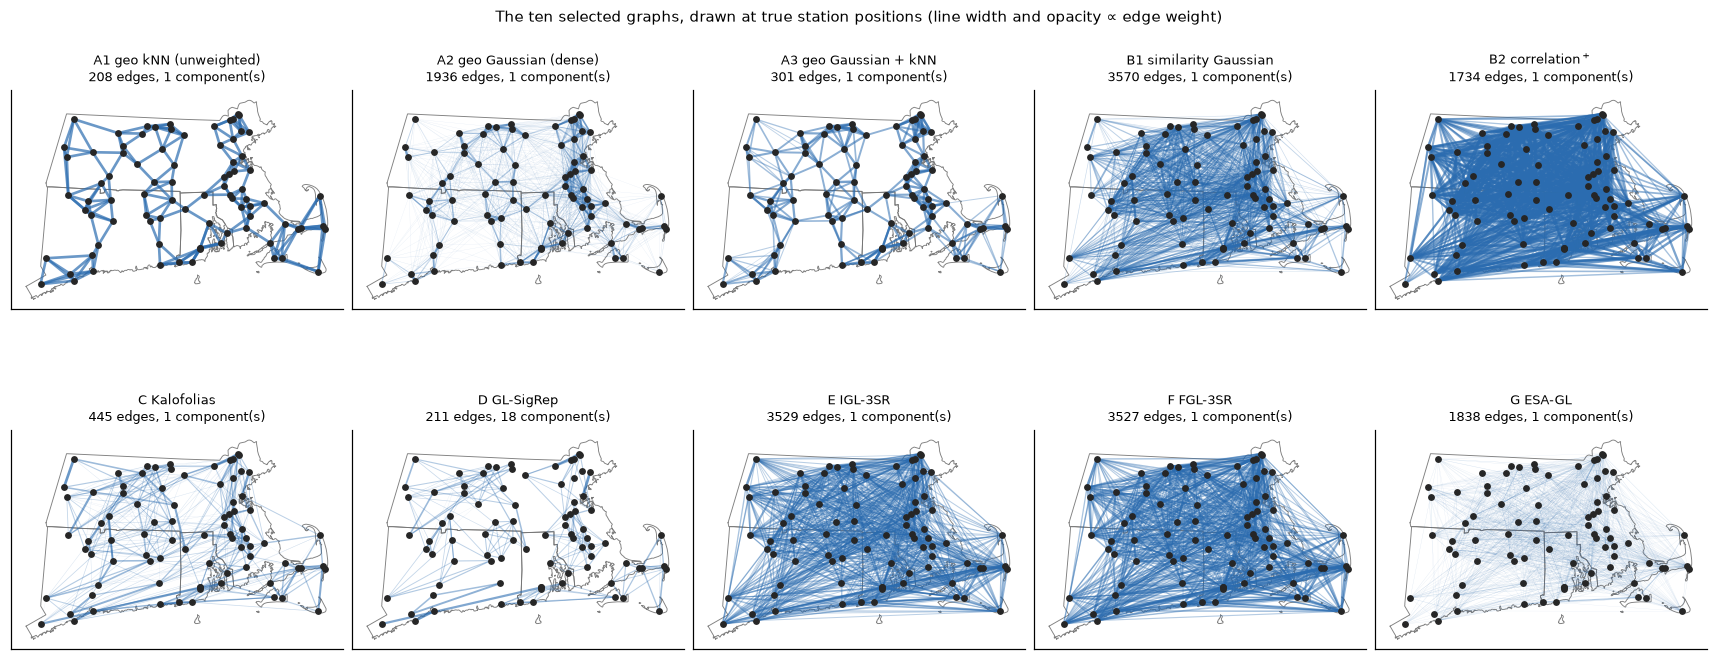

In [26]:
fig, axes = plt.subplots(2, 5, figsize=(15.5, 6.4))
for ax, nm in zip(axes.ravel(), NAMES):
    plot_graph(nm, ax)
for ax in axes.ravel()[len(NAMES):]:
    ax.axis("off")
fig.suptitle("The ten selected graphs, drawn at true station positions "
             "(line width and opacity ∝ edge weight)", fontsize=10)
plt.show()

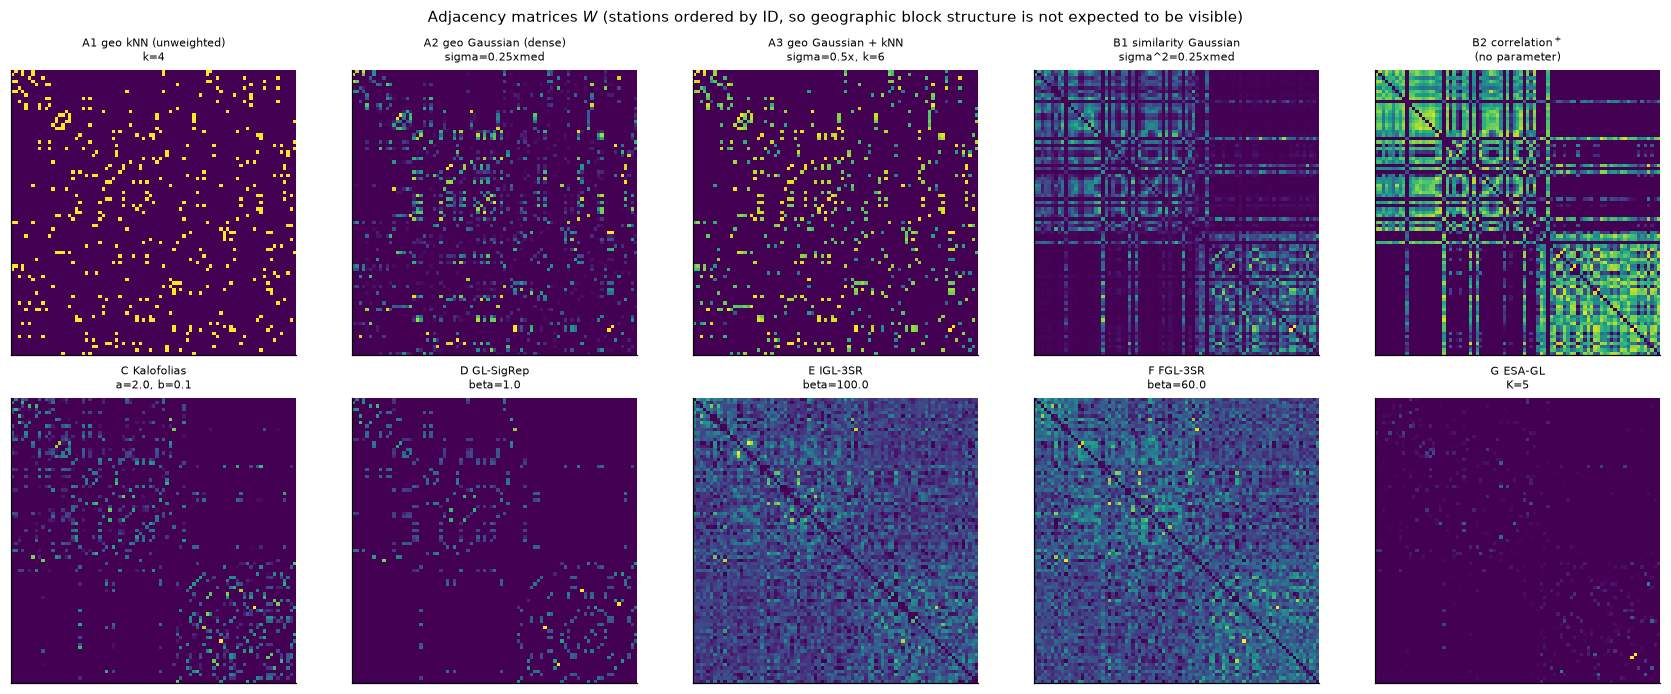

In [27]:
fig, axes = plt.subplots(2, 5, figsize=(15.5, 6.2))
for ax, nm in zip(axes.ravel(), NAMES):
    W = ei.W(GRAPHS[nm]["w"])
    ax.imshow(W, cmap="viridis")
    ax.set_title(f"{nm}\n{GRAPHS[nm]['setting']}", fontsize=7.5)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for ax in axes.ravel()[len(NAMES):]:
    ax.axis("off")
fig.suptitle("Adjacency matrices $W$ (stations ordered by ID, so geographic block "
             "structure is not expected to be visible)", fontsize=10)
plt.show()

In [28]:
rows = []
for nm in NAMES:
    g = GRAPHS[nm]; w = g["w"]; L = g["L"]; lam = g["lam"]
    deg = ei.W(w).sum(1)
    nz = int((w > 1e-8 * w.max()).sum())
    rows.append(dict(method=nm, setting=g["setting"],
                     edges=nz, density=100 * nz / ei.m,
                     comps=gl.n_components(L),
                     lam2=lam[1], lam_max=lam[-1],
                     deg_min=deg.min(), deg_max=deg.max(),
                     val_rmse=g["val_rmse"]))
summary = pd.DataFrame(rows).set_index("method")
print(summary.to_string(float_format=lambda v: f"{v:.4g}"))
print("\nrepeated eigenvalues (multiplicity > 1, tolerance 1e-6):")
for nm in NAMES:
    lam = GRAPHS[nm]["lam"]
    d = np.diff(lam)
    reps = int((d < 1e-6).sum())
    print(f"  {nm:28s} {reps:3d} near-equal adjacent pairs"
          + ("   <- individual eigenvector ordering is arbitrary there" if reps > 2 else ""))

                                  setting  edges  density  comps      lam2  lam_max   deg_min  deg_max  val_rmse
method                                                                                                          
A1 geo kNN (unweighted)               k=4    208    5.826      1  0.004477    1.881    0.8173    1.635     2.396
A2 geo Gaussian (dense)    sigma=0.25xmed   1936    54.23      1   0.01468    2.253   0.08519     2.03     2.377
A3 geo Gaussian + kNN     sigma=0.5x, k=6    301    8.431      1   0.01229    1.845    0.5146    1.603     2.373
B1 similarity Gaussian   sigma^2=0.25xmed   3570      100      1   0.06987    1.613    0.2155    1.543     1.667
B2 correlation$^+$         (no parameter)   1734    48.57      1   0.01519    1.315     0.151    1.277     1.839
C Kalofolias                 a=2.0, b=0.1    445    12.46      1  0.001699    1.697    0.2481    1.415     1.267
D GL-SigRep                      beta=1.0    211     5.91     18 7.711e-11    1.441 1.137e-10   

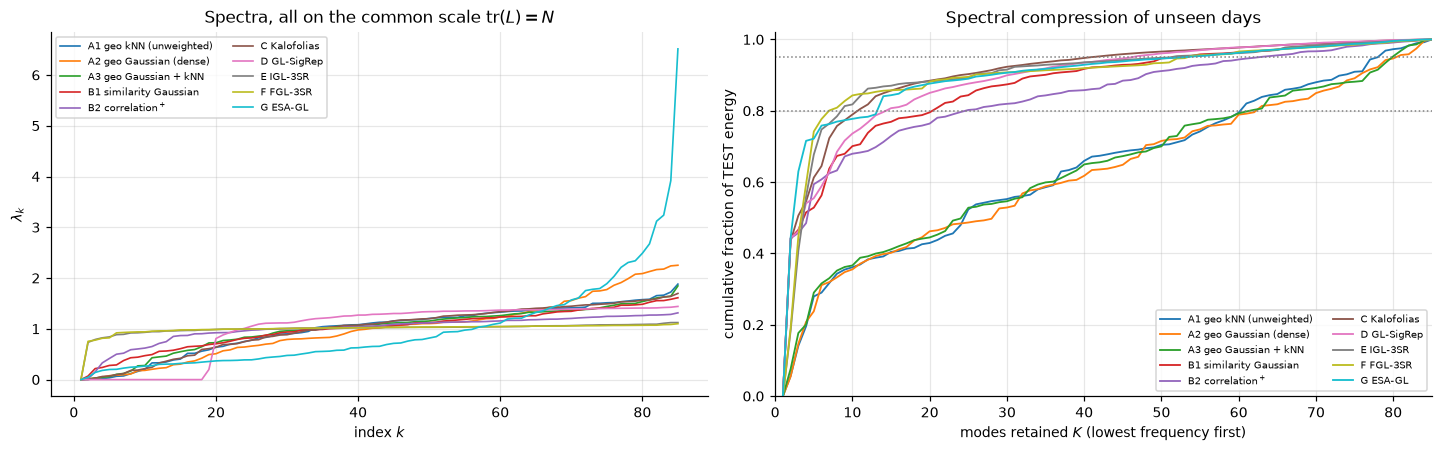

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.0))
for nm in NAMES:
    axes[0].plot(np.arange(1, N + 1), GRAPHS[nm]["lam"], lw=1.1, label=nm)
axes[0].set_xlabel("index $k$"); axes[0].set_ylabel(r"$\lambda_k$")
axes[0].set_title("Spectra, all on the common scale $\\mathrm{tr}(L)=N$")
axes[0].legend(fontsize=6.5, ncol=2)

for nm in NAMES:
    U = np.linalg.eigh(GRAPHS[nm]["L"])[1]
    E = (U.T @ Ztest) ** 2
    cum = np.cumsum(E.sum(1)) / E.sum()
    axes[1].plot(np.arange(1, N + 1), cum, lw=1.2, label=nm)
axes[1].axhline(0.8, color="gray", ls=":", lw=1); axes[1].axhline(0.95, color="gray", ls=":", lw=1)
axes[1].set_xlabel("modes retained $K$ (lowest frequency first)")
axes[1].set_ylabel("cumulative fraction of TEST energy")
axes[1].set_title("Spectral compression of unseen days")
axes[1].set_xlim(0, N); axes[1].set_ylim(0, 1.02)
axes[1].legend(fontsize=6.5, ncol=2)
plt.show()

### 4.1 Two different things called "coefficients"

A subtlety that is easy to get wrong. During training, the GL-3SR and ESA-GL methods produce a
coefficient matrix $H$ — but $H$ is **regularised**: it is a shrunken, row-sparsified object fitted
jointly with the basis. It is *not* the transform of the data.

What we evaluate on test days is the honest thing: $U^\top Z_{\text{test}}$, the plain GFT of unseen
observations in the learned basis, with no shrinkage. Reporting the training $H$ as though it were a
test spectrum would flatter every sparsity-seeking method enormously, because $H$ was *built* to have
few nonzero rows.


In [30]:
print(f"{'method':28s}{'K for 50%':>11s}{'K for 80%':>11s}{'K for 95%':>11s}"
      f"{'Dirichlet/edge':>16s}")
energy_rows = []
for nm in NAMES:
    L = GRAPHS[nm]["L"]
    U = np.linalg.eigh(L)[1]
    E = ((U.T @ Ztest) ** 2).sum(1)
    cum = np.cumsum(E) / E.sum()
    k50, k80, k95 = [int(np.searchsorted(cum, q) + 1) for q in (0.5, 0.8, 0.95)]
    w = GRAPHS[nm]["w"]
    nz = max(int((w > 1e-8 * w.max()).sum()), 1)
    de = dirichlet(Ztest, w) / Ztest.shape[1] / nz
    energy_rows.append(dict(method=nm, k50=k50, k80=k80, k95=k95, dir_per_edge=de))
    print(f"{nm:28s}{k50:11d}{k80:11d}{k95:11d}{de:16.4g}")
energy_df = pd.DataFrame(energy_rows).set_index("method")

# Contrast with the TRAINING H for the sparsity-seeking methods.
print("\nFor contrast -- the regularised training H of the 3SR/ESA methods:")
import glob as _glob
for pref, lab in [("fgl_", "F FGL-3SR"), ("igl_", "E IGL-3SR")]:
    beta = SELECTED[lab]['label'].split('=')[1]
    hits = _glob.glob(os.path.join(CACHE_DIR, f"{pref}b{float(beta)}__*.npz"))
    if hits:
        H = np.load(hits[0], allow_pickle=True)["H"]
        nz = int((np.linalg.norm(H, axis=1) > 1e-8).sum())
        kk = int(energy_df.loc[lab, "k80"])
        print(f"  {lab} (beta={beta}): training H has {nz} nonzero rows of {N}, "
              f"but {kk} modes are needed for 80% of TEST energy")
print("  -> H is a fitted, shrunken object. Quoting its row count as a compression")
print("     result would flatter every sparsity-seeking method enormously.")

method                        K for 50%  K for 80%  K for 95%  Dirichlet/edge
A1 geo kNN (unweighted)              25         61         78           2.323
A2 geo Gaussian (dense)              29         63         81          0.2607
A3 geo Gaussian + kNN                25         62         80           1.611
B1 similarity Gaussian                4         21         53         0.07173
B2 correlation$^+$                    5         25         63          0.1697
C Kalofolias                          3         11         41          0.2957
D GL-SigRep                           4         15         47          0.6037
E IGL-3SR                             4          9         52          0.1602
F FGL-3SR                             4          7         54          0.1591
G ESA-GL                              3         14         53          0.0839

For contrast -- the regularised training H of the 3SR/ESA methods:
  F FGL-3SR (beta=60.0): training H has 21 nonzero rows of 85, but 7 modes

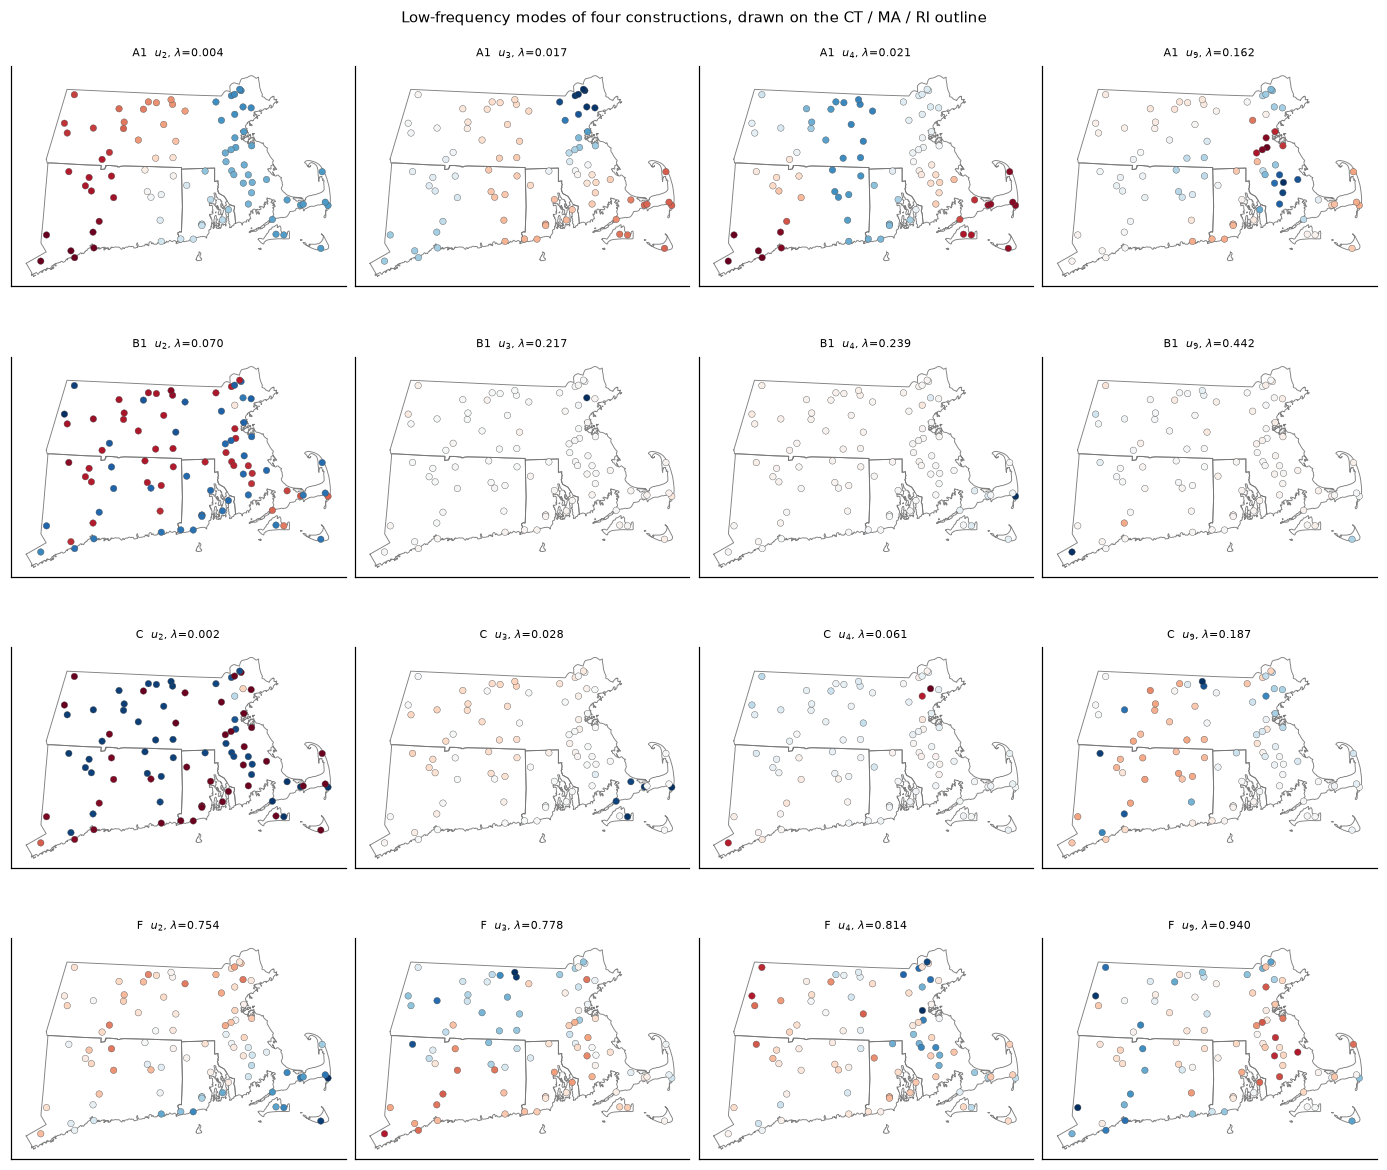

graph                       |corr(u_2, easting)|  |corr(u_2, northing)|  stations u_2 lives on
A1 geo kNN (unweighted)                    0.925                  0.069               52.6 of 85
B1 similarity Gaussian                     0.131                  0.205               81.2 of 85
C Kalofolias                               0.119                  0.203               82.1 of 85
F FGL-3SR                                  0.497                  0.595               25.3 of 85

The geographic graph's u_2 is a clean west-east gradient, because its edges were
built from exactly that. The learned graphs do NOT reproduce it: their u_2
correlates at most 0.50 with easting against 0.92 for the
geographic graph. Learning from temperatures found structure that is not a simple
spatial gradient -- and those same graphs reconstruct far better, so the structure
they found is evidently the more useful one. Read the numbers before the pictures:
a mode living on 25 of 85 stations can look organised 

In [31]:
# --- selected low-frequency modes, drawn geographically -----------------------
SHOW = ["A1 geo kNN (unweighted)", "B1 similarity Gaussian", "C Kalofolias", "F FGL-3SR"]
fig, axes = plt.subplots(len(SHOW), 4, figsize=(12.5, 2.7 * len(SHOW)))
for r_, nm in enumerate(SHOW):
    U = np.linalg.eigh(GRAPHS[nm]["L"])[1]
    lam = GRAPHS[nm]["lam"]
    for c_, k in enumerate([1, 2, 3, 8]):
        ax = axes[r_, c_]
        v = U[:, k]; mm = np.abs(v).max()
        draw_states(ax)                  # CT / MA / RI borders, nothing else
        ax.scatter(P[:, 0] / 1000, P[:, 1] / 1000, c=v, cmap="RdBu_r",
                   vmin=-mm, vmax=mm, s=18, edgecolor="0.3", linewidth=0.25, zorder=3)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"{nm.split(' ')[0]}  $u_{{{k+1}}}$, $\\lambda$={lam[k]:.3f}", fontsize=7.5)
fig.suptitle("Low-frequency modes of four constructions, drawn on the CT / MA / RI outline",
             fontsize=10)
plt.show()

# Is a mode "geographic"? Measure it rather than eyeball it: how strongly does u_2
# line up with the east-west axis, and how many stations does it actually live on?
print(f"{'graph':26s}{'|corr(u_2, easting)|':>22s}{'|corr(u_2, northing)|':>23s}"
      f"{'stations u_2 lives on':>23s}")
for nm in SHOW:
    U = np.linalg.eigh(GRAPHS[nm]["L"])[1]
    u = U[:, 1]
    pr = 1.0 / np.sum(u ** 4)          # participation ratio
    print(f"{nm:26s}{abs(np.corrcoef(u, P[:, 0])[0, 1]):22.3f}"
          f"{abs(np.corrcoef(u, P[:, 1])[0, 1]):23.3f}{pr:19.1f} of {N}")
print()
_gc = {nm: abs(np.corrcoef(np.linalg.eigh(GRAPHS[nm]["L"])[1][:, 1], P[:, 0])[0, 1])
       for nm in SHOW}
_learned = [nm for nm in SHOW if not nm.startswith("A")]
print("The geographic graph's u_2 is a clean west-east gradient, because its edges were")
print("built from exactly that. The learned graphs do NOT reproduce it: their u_2")
print(f"correlates at most {max(_gc[n] for n in _learned):.2f} with easting against "
      f"{_gc[SHOW[0]]:.2f} for the")
print("geographic graph. Learning from temperatures found structure that is not a simple")
print("spatial gradient -- and those same graphs reconstruct far better, so the structure")
print("they found is evidently the more useful one. Read the numbers before the pictures:")
print("a mode living on 25 of 85 stations can look organised purely by concentration.")

### 4.2 Missing-station reconstruction on test days

The headline task. Identical hidden-station masks for every method, the frozen $\gamma$ from
validation, and errors in degrees Celsius.

**Baselines**, all graph-free:

- **Visible-mean** — predict the mean of the visible stations. This is what the reconstruction returns
  as $\gamma\to\infty$, and it is the number every method must beat to have earned its complexity.
- **Elevation regression** — Lesson 3's winner. Fit $z \sim \text{elevation}$ on training days, then
  predict the anomaly at hidden stations from their elevation.
- **PCA at matched dimension** — fit PCA on the training anomalies, then estimate the scores from the
  visible stations by least squares and reconstruct the hidden ones. This is the strongest baseline:
  it also learns spatial structure from the same training data, just without any graph.


In [32]:
# --- baselines ---------------------------------------------------------------
b_elev = np.column_stack([np.ones(N), elev, elev ** 2])
coef_elev, *_ = np.linalg.lstsq(b_elev, Ztrain.mean(axis=1), rcond=None)
elev_pred = b_elev @ coef_elev          # a static per-station anomaly offset

pca_mean = Ztrain.mean(axis=1, keepdims=True)
Uc, Sc, _ = np.linalg.svd(Ztrain - pca_mean, full_matrices=False)

def predict_baseline(kind, y, hidden, n_comp=None):
    obs_idx = np.setdiff1d(np.arange(N), hidden)
    lvl = y[obs_idx].mean()
    z = y - lvl
    if kind == "mean":
        zh = np.zeros(N)
    elif kind == "elev":
        zh = elev_pred.copy()
    elif kind == "pca":
        B = Uc[:, :n_comp]
        c, *_ = np.linalg.lstsq(B[obs_idx], (z - pca_mean.ravel())[obs_idx], rcond=None)
        zh = pca_mean.ravel() + B @ c
    return zh + lvl

def eval_baseline(kind, day_idx, masks, n_comp=None):
    errs = []
    for t in day_idx:
        y = Y[:, t]
        for hid in masks[t]:
            errs.append(predict_baseline(kind, y, hid, n_comp)[hid] - y[hid])
    e = np.concatenate(errs)
    return float(np.sqrt(np.mean(e ** 2)))

# PCA dimension chosen on validation, like every other hyperparameter
pca_grid = [1, 2, 3, 5, 8, 12, 20]
pca_val = {k: eval_baseline("pca", val_days, val_masks, k) for k in pca_grid}
PCA_K = min(pca_val, key=pca_val.get)
print("PCA components (validation RMSE):",
      {k: round(v, 4) for k, v in pca_val.items()}, f"-> chose K={PCA_K}")

PCA components (validation RMSE): {1: 1.8887, 2: 1.4968, 3: 1.3875, 5: 1.2543, 8: 1.2033, 12: 1.2304, 20: 1.3199} -> chose K=8


In [33]:
def per_day_errors(w=None, gamma=None, kind=None, n_comp=None):
    """Return (per-mask RMSE array, per-day RMSE array) on the test block."""
    L = L_of(trace_normalised(w)) if w is not None else None
    per_mask, per_day = [], []
    for t in test_days:
        y = Y[:, t]; day_err = []
        for hid in test_masks[t]:
            yh = (reconstruct_day(L, y, hid, gamma) if L is not None
                  else predict_baseline(kind, y, hid, n_comp))
            e = yh[hid] - y[hid]
            per_mask.append(np.sqrt(np.mean(e ** 2)))
            day_err.append(e)
        per_day.append(np.sqrt(np.mean(np.concatenate(day_err) ** 2)))
    return np.array(per_mask), np.array(per_day)

results = {}
for nm in NAMES:
    g = GRAPHS[nm]
    pm, pd_ = per_day_errors(w=g["w"], gamma=g["gamma"])
    results[nm] = dict(rmse=float(np.sqrt(np.mean(pm ** 2))), per_day=pd_, kind="graph")
for lab, kind, nc in [("baseline: visible mean", "mean", None),
                      ("baseline: elevation", "elev", None),
                      (f"baseline: PCA (K={PCA_K})", "pca", PCA_K)]:
    pm, pd_ = per_day_errors(kind=kind, n_comp=nc)
    results[lab] = dict(rmse=float(np.sqrt(np.mean(pm ** 2))), per_day=pd_, kind="baseline")

order = sorted(results, key=lambda k: results[k]["rmse"])
print(f"{'':4s}{'method':30s}{'test RMSE':>11s}{'vs visible-mean':>17s}{'val RMSE':>11s}")
base = results["baseline: visible mean"]["rmse"]
for i, nm in enumerate(order, 1):
    r = results[nm]
    vr = f"{GRAPHS[nm]['val_rmse']:.4f}" if nm in GRAPHS else "-"
    print(f"{i:<4d}{nm:30s}{r['rmse']:11.4f}{100*(r['rmse']-base)/base:+16.1f}%{vr:>11s}")

    method                          test RMSE  vs visible-mean   val RMSE
1   baseline: PCA (K=8)                1.2381           -56.5%          -
2   C Kalofolias                       1.2901           -54.7%     1.2673
3   G ESA-GL                           1.4045           -50.6%     1.3816
4   D GL-SigRep                        1.4627           -48.6%     1.4296
5   B1 similarity Gaussian             1.7057           -40.1%     1.6669
6   B2 correlation$^+$                 1.8671           -34.4%     1.8389
7   A3 geo Gaussian + kNN              2.4753           -13.0%     2.3727
8   F FGL-3SR                          2.4761           -13.0%     2.3761
9   E IGL-3SR                          2.4904           -12.5%     2.3935
10  A2 geo Gaussian (dense)            2.4973           -12.2%     2.3768
11  A1 geo kNN (unweighted)            2.5052           -12.0%     2.3958
12  baseline: elevation                2.7881            -2.0%          -
13  baseline: visible mean            

C:\Users\steve\AppData\Local\Temp\ipykernel_26576\2194934058.py:13: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = axes[1].boxplot(data, vert=False, widths=0.6, patch_artist=True,


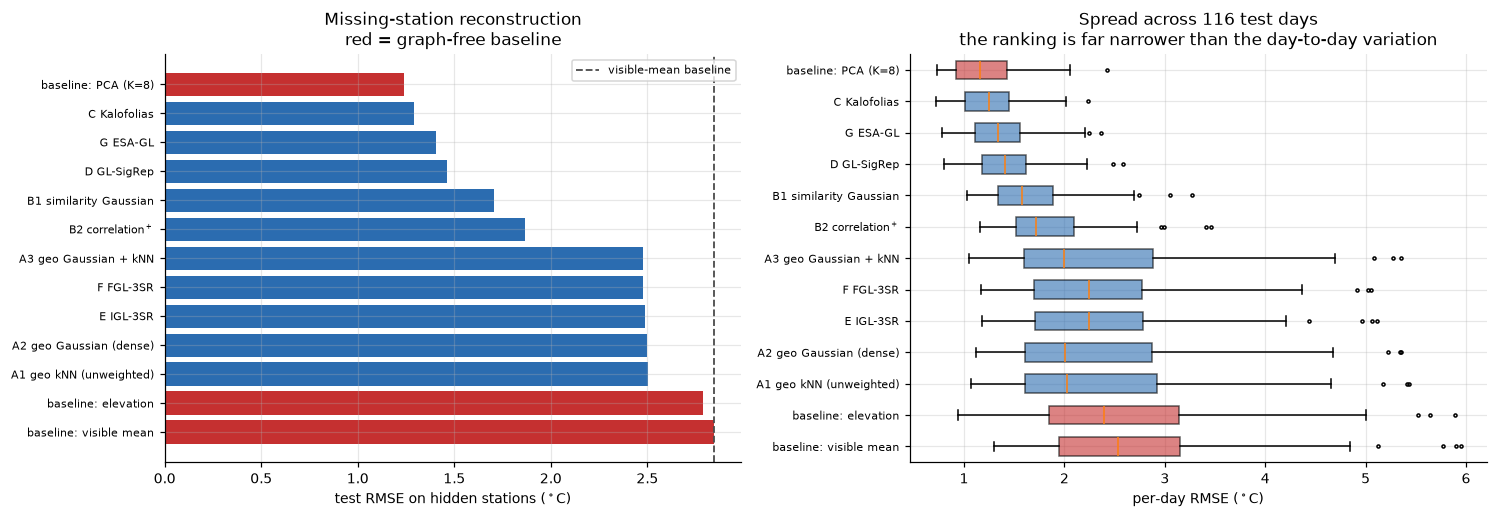

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
cols = [C_RED if results[n]["kind"] == "baseline" else C_LINE for n in order]
axes[0].barh(range(len(order)), [results[n]["rmse"] for n in order], color=cols)
axes[0].set_yticks(range(len(order)))
axes[0].set_yticklabels(order, fontsize=7)
axes[0].invert_yaxis()
axes[0].axvline(base, color="0.3", ls="--", lw=1.2, label="visible-mean baseline")
axes[0].set_xlabel("test RMSE on hidden stations ($^\\circ$C)")
axes[0].set_title("Missing-station reconstruction\nred = graph-free baseline")
axes[0].legend(fontsize=7.5)

data = [results[n]["per_day"] for n in order]
bp = axes[1].boxplot(data, vert=False, widths=0.6, patch_artist=True,
                     flierprops=dict(markersize=2))
for patch, c in zip(bp["boxes"], cols):
    patch.set_facecolor(c); patch.set_alpha(0.6)
axes[1].set_yticks(range(1, len(order) + 1)); axes[1].set_yticklabels(order, fontsize=7)
axes[1].invert_yaxis()
axes[1].set_xlabel("per-day RMSE ($^\\circ$C)")
axes[1].set_title(f"Spread across {len(test_days)} test days\n"
                  "the ranking is far narrower than the day-to-day variation")
plt.show()

In [35]:
# --- is the gap larger than the day-to-day noise? -----------------------------
best_graph = next(n for n in order if results[n]["kind"] == "graph")
print(f"best graph method   : {best_graph}  ({results[best_graph]['rmse']:.4f} degC)")
print(f"best baseline       : "
      f"{min((n for n in order if results[n]['kind']=='baseline'), key=lambda n: results[n]['rmse'])}"
      f"  ({min(results[n]['rmse'] for n in order if results[n]['kind']=='baseline'):.4f} degC)")
print()
for a, b in [(best_graph, f"baseline: PCA (K={PCA_K})"),
             (best_graph, "baseline: visible mean"),
             ("A1 geo kNN (unweighted)", best_graph)]:
    da, db = results[a]["per_day"], results[b]["per_day"]
    diff = da - db
    se = diff.std(ddof=1) / np.sqrt(len(diff))
    print(f"{a[:26]:26s} - {b[:26]:26s}: mean diff {diff.mean():+.4f} degC, "
          f"paired SE {se:.4f}  -> {'distinguishable' if abs(diff.mean()) > 2*se else 'NOT distinguishable'}")
print("\n(paired across test days, so day-to-day weather variation cancels)")

best graph method   : C Kalofolias  (1.2901 degC)
best baseline       : baseline: PCA (K=8)  (1.2381 degC)

C Kalofolias               - baseline: PCA (K=8)       : mean diff +0.0614 degC, paired SE 0.0185  -> distinguishable
C Kalofolias               - baseline: visible mean    : mean diff -1.4194 degC, paired SE 0.0785  -> distinguishable
A1 geo kNN (unweighted)    - C Kalofolias              : mean diff +1.0614 degC, paired SE 0.0810  -> distinguishable

(paired across test days, so day-to-day weather variation cancels)


In [36]:
# --- seasonal breakdown and runtime ------------------------------------------
season_of = {1:"DJF",2:"DJF",12:"DJF",3:"MAM",4:"MAM",5:"MAM",
             6:"JJA",7:"JJA",8:"JJA",9:"SON",10:"SON",11:"SON"}
test_season = np.array([season_of[dates[t].month] for t in test_days])
show_rows = [order[0], best_graph, "A1 geo kNN (unweighted)",
             f"baseline: PCA (K={PCA_K})", "baseline: visible mean"]
show_rows = list(dict.fromkeys(show_rows))
print(f"{'method':30s}" + "".join(f"{s:>9s}" for s in ["DJF","MAM","JJA","SON"]) + f"{'all':>9s}")
for nm in show_rows:
    pdv = results[nm]["per_day"]
    line = f"{nm:30s}"
    for s in ["DJF","MAM","JJA","SON"]:
        sel = test_season == s
        line += f"{np.sqrt(np.mean(pdv[sel]**2)):9.3f}"
    line += f"{results[nm]['rmse']:9.3f}"
    print(line)
worst = max(["DJF", "MAM", "JJA", "SON"],
            key=lambda s_: np.sqrt(np.mean(results["baseline: visible mean"]["per_day"]
                                           [test_season == s_] ** 2)))
print(f"\n(RMSE in degC by meteorological season. The hardest season here is {worst}:")
print(" spring has the largest within-day spatial spread in this region, because")
print(" land and sea warm at different rates. The ranking of methods, not the level,")
print(" is what transfers across seasons.)")

method                              DJF      MAM      JJA      SON      all
baseline: PCA (K=8)               1.314    1.328    1.097    1.150    1.238
C Kalofolias                      1.286    1.381    1.250    1.178    1.290
A1 geo kNN (unweighted)           2.256    2.950    2.221    2.265    2.505
baseline: visible mean            2.652    3.321    2.571    2.476    2.845

(RMSE in degC by meteorological season. The hardest season here is MAM:
 spring has the largest within-day spatial spread in this region, because
 land and sea warm at different rates. The ranking of methods, not the level,
 is what transfers across seasons.)


In [37]:
RUNTIME = {}
for key, meth in [("kalo", "C Kalofolias"), ("glsig", "D GL-SigRep"),
                  ("igl", "E IGL-3SR"), ("fgl", "F FGL-3SR"), ("esa", "G ESA-GL")]:
    secs = []
    for f in os.listdir(CACHE_DIR):
        if f.startswith(key + "_") and f.endswith(".npz"):
            d = np.load(os.path.join(CACHE_DIR, f), allow_pickle=True)
            if "seconds" in d.files:
                secs.append(float(d["seconds"]))
    if secs:
        RUNTIME[meth] = (np.mean(secs), len(secs))
for meth in ["A1 geo kNN (unweighted)", "A2 geo Gaussian (dense)", "A3 geo Gaussian + kNN",
             "B1 similarity Gaussian", "B2 correlation$^+$"]:
    RUNTIME[meth] = (0.0, 1)
print(f"{'method':30s}{'mean fit (s)':>14s}{'fits run':>10s}")
for meth in NAMES:
    s, n_ = RUNTIME.get(meth, (float("nan"), 0))
    print(f"{meth:30s}{s:14.2f}{n_:10d}")
print("\n(closed-form constructions are reported as 0.00 s: a single matrix expression;")
print(" learned-method times are the mean over the fits actually run in this session,")
print(" and are 0 when every fit was served from cache -- rerun after clearing")
print(f" {CACHE_DIR} to time them from cold)")

method                          mean fit (s)  fits run
A1 geo kNN (unweighted)                 0.00         1
A2 geo Gaussian (dense)                 0.00         1
A3 geo Gaussian + kNN                   0.00         1
B1 similarity Gaussian                  0.00         1
B2 correlation$^+$                      0.00         1
C Kalofolias                            0.07         9
D GL-SigRep                             0.78         5
E IGL-3SR                              10.07         3
F FGL-3SR                              20.03         3
G ESA-GL                               19.50         3

(closed-form constructions are reported as 0.00 s: a single matrix expression;
 learned-method times are the mean over the fits actually run in this session,
 and are 0 when every fit was served from cache -- rerun after clearing
 data\fits to time them from cold)


---
## 5. Verdict, table, and verification


In [38]:
tbl = []
ASSUMPTION = {
 "A1 geo kNN (unweighted)": "proximity implies coupling; unweighted",
 "A2 geo Gaussian (dense)": "coupling decays with distance",
 "A3 geo Gaussian + kNN": "as A2, truncated to k nearest",
 "B1 similarity Gaussian": "similar histories imply an edge",
 "B2 correlation$^+$": "positive co-variation implies an edge",
 "C Kalofolias": "signals are smooth on the graph",
 "D GL-SigRep": "observations are noisy; latent field is smooth",
 "E IGL-3SR": "shared sparse spectral support + smoothness",
 "F FGL-3SR": "as IGL, with a relaxed basis update",
 "G ESA-GL": "shared sparse support; topology fits it afterwards",
}
CONCLUSION = {}
for nm in NAMES:
    g = GRAPHS[nm]
    r = results[nm]
    e = energy_df.loc[nm]
    tbl.append(dict(method=nm, assumption=ASSUMPTION[nm], setting=g["setting"],
                    gamma=g["gamma"], val=round(g["val_rmse"], 4),
                    test=round(r["rmse"], 4),
                    vs_mean=f"{100*(r['rmse']-base)/base:+.1f}%",
                    edges=int((g["w"] > 1e-8 * g["w"].max()).sum()),
                    comps=gl.n_components(g["L"]),
                    K80=int(e["k80"]),
                    fit_s=round(RUNTIME.get(nm, (float('nan'), 0))[0], 2)))
final = pd.DataFrame(tbl).set_index("method")
print(final.to_string())
final.to_csv(os.path.join(DATA_DIR, "lesson4_comparison.csv"))
print(f"\nsaved -> {os.path.join(DATA_DIR, 'lesson4_comparison.csv')}")

                                                                 assumption           setting  gamma     val    test vs_mean  edges  comps  K80  fit_s
method                                                                                                                                                
A1 geo kNN (unweighted)              proximity implies coupling; unweighted               k=4   10.0  2.3958  2.5052  -12.0%    208      1   61   0.00
A2 geo Gaussian (dense)                       coupling decays with distance    sigma=0.25xmed    3.0  2.3768  2.4973  -12.2%   1936      1   63   0.00
A3 geo Gaussian + kNN                         as A2, truncated to k nearest   sigma=0.5x, k=6    3.0  2.3727  2.4753  -13.0%    301      1   62   0.00
B1 similarity Gaussian                      similar histories imply an edge  sigma^2=0.25xmed    0.1  1.6669  1.7057  -40.1%   3570      1   21   0.00
B2 correlation$^+$                    positive co-variation implies an edge    (no parameter) 

In [39]:
tol = 1e-8
checks = []
def check(name, ok, detail=""):
    checks.append((name, bool(ok), detail))

# --- data integrity -----------------------------------------------------------
check("station order is canonical and unique",
      len(station_ids) == len(set(station_ids)) == N)
check("metadata rows align with the signal matrix",
      meta["station"].tolist() == station_ids)
check("coordinates and elevations finite",
      np.all(np.isfinite(P)) and np.all(np.isfinite(elev)))
check("no -9999 sentinel survived into Y", not np.any(np.isclose(np.nan_to_num(Y, nan=0), -999.9)))
check("all retained TMAX physically plausible",
      np.nanmin(Y) > -60 and np.nanmax(Y) < 55, f"{np.nanmin(Y):.1f}..{np.nanmax(Y):.1f} degC")
check("flagged observations were actually removed",
      int((notmiss & ~passedqc).sum()) > 0 and
      not obs["qflag"].ne("").any(), f"{int((notmiss & ~passedqc).sum())} dropped")

# --- experiment hygiene -------------------------------------------------------
check("train / val / test day sets are disjoint",
      len(set(train_days) & set(val_days)) == 0 and
      len(set(val_days) & set(test_days)) == 0 and
      len(set(train_days) & set(test_days)) == 0)
n_adjacent = sum(1 for a in train_days for b in test_days if abs(a - b) == 1)
check("no training day is adjacent to a test day", n_adjacent == 0,
      f"{n_adjacent} adjacent pairs")
check("evaluation blocks contain no imputed values",
      bool(observed[:, val_days].all() and observed[:, test_days].all()))
check("every split covers every month",
      all(set(pd.Series(dates[m]).dt.month.unique()) == set(range(1, 13))
          for m in (train_days, val_days, test_days)))
check("daily centring uses visible stations only (columns sum to zero)",
      float(np.nanmax(np.abs(np.nansum(Zfull[:, complete_day], axis=0)))) < 1e-9)
n_hide = int(round(MASK_FRACTION * N))
check("hidden-station masks are well formed and fixed",
      all(len(m) == n_hide and len(set(m.tolist())) == n_hide
          for t in test_days for m in test_masks[t])
      and all(np.array_equal(a, b) for a, b in
              zip(test_masks[test_days[0]],
                  make_masks(test_days, MASK_REPEATS, MASK_FRACTION, SEED + 1000)[test_days[0]])),
      f"{n_hide} hidden of {N}, regenerating from the seed reproduces them")

# --- every learned operator is a valid Laplacian -------------------------------
for nm in NAMES:
    g = GRAPHS[nm]; w = g["w"]; L = g["L"]; lam = g["lam"]
    check(f"[{nm}] weights nonnegative", float(w.min()) >= -tol, f"min {w.min():.2e}")
    check(f"[{nm}] L symmetric, zero row sums, off-diagonals <= 0",
          np.allclose(L, L.T) and np.abs(L @ np.ones(N)).max() < 1e-9
          and (L - np.diag(np.diag(L))).max() <= tol)
    check(f"[{nm}] trace normalised to N", np.isclose(np.trace(L), N),
          f"tr={np.trace(L):.6f}")
    check(f"[{nm}] eigenvalues nonnegative", lam.min() > -1e-8, f"min {lam.min():.2e}")
    check(f"[{nm}] zero-eigenvalue count == component count",
          int((lam < 1e-8).sum()) == gl.n_components(L))
    U = np.linalg.eigh(L)[1]
    check(f"[{nm}] eigenpair residual",
          max(np.abs(L @ U[:, k] - lam[k] * U[:, k]).max() for k in range(N)) < 1e-8)
    check(f"[{nm}] GFT inverts on test data",
          np.abs(U @ (U.T @ Ztest) - Ztest).max() < 1e-9)
    check(f"[{nm}] Parseval on test data",
          np.isclose(np.sum(Ztest ** 2), np.sum((U.T @ Ztest) ** 2)))
    check(f"[{nm}] Dirichlet edge form == matrix form",
          np.isclose(dirichlet(Ztest, w), np.trace(Ztest.T @ L @ Ztest)))

# --- algorithm-specific ---------------------------------------------------------
check("GL-3SR basis keeps the constant eigenvector",
      np.allclose(np.abs(gl._U0_complete(N)[:, 0]), 1 / np.sqrt(N)))
check("H-step l0 branch does not overwrite trailing rows (reference bug fixed)",
      int(np.sum(np.linalg.norm(
          gl._H_step(gl._U0_complete(N), Ztrain,
                     np.r_[0.0, np.full(N - 1, N / (N - 1))], 1.0, 80.0, "l0"),
          axis=1) > 0)) > 1)
check("reconstruction reduces to the visible mean as gamma -> infinity",
      abs(float(np.sqrt(np.mean((reconstruct_day(GRAPHS[NAMES[0]]["L"], Y[:, test_days[0]],
                                                 test_masks[test_days[0]][0], 1e9)
                                 - Y[:, test_days[0]])[test_masks[test_days[0]][0]] ** 2)))
          - float(np.sqrt(np.mean((predict_baseline("mean", Y[:, test_days[0]],
                                                    test_masks[test_days[0]][0])
                                   - Y[:, test_days[0]])[test_masks[test_days[0]][0]] ** 2)))) < 1e-3)
check("test RMSE was computed on genuine observations only",
      bool(observed[:, test_days].all()))

width = max(len(n) for n, _, _ in checks)
for n, ok, d in checks:
    print(f"{'PASS' if ok else 'FAIL'}  {n:<{width}}  {d}")
bad = [n for n, ok, _ in checks if not ok]
assert not bad, f"failed checks: {bad}"
print(f"\nAll {len(checks)} checks passed.")

PASS  station order is canonical and unique                                     


PASS  metadata rows align with the signal matrix                                
PASS  coordinates and elevations finite                                         
PASS  no -9999 sentinel survived into Y                                         
PASS  all retained TMAX physically plausible                                    -17.2..37.8 degC
PASS  flagged observations were actually removed                                28 dropped
PASS  train / val / test day sets are disjoint                                  
PASS  no training day is adjacent to a test day                                 0 adjacent pairs
PASS  evaluation blocks contain no imputed values                               
PASS  every split covers every month                                            
PASS  daily centring uses visible stations only (columns sum to zero)           
PASS  hidden-station masks are well formed and fixed                            17 hidden of 85, regenerating from the seed reproduces them
PASS  [

---
## Applied conclusion

**The question was: does learning connections from repeated observations improve graph
representation and missing-value reconstruction over geographic graphs, and does the improvement
generalise beyond the days used to learn?**

### When did learning the graph beat geography?

**Decisively, and it generalised.** On 116 fully observed test days spread across 2015-2017, hiding
17 of 85 stations:

| | test RMSE (°C) |
|---|---|
| best learned graph — **Kalofolias** | **1.290** |
| best geographic graph — Gaussian + $k$-NN | 2.475 |
| visible-mean baseline | 2.845 |

That is a **48% error reduction** over the best geographic construction. The paired per-day
difference (1.061 °C, standard error 0.081) is thirteen standard errors — far larger than the
day-to-day variation it is measured against — and the validation and test orderings agree method for
method. The graph learned from 439 training days genuinely transfers to days it never saw.

Lesson 3's finding is reversed on its own terms. There, a two-parameter elevation regression beat six
to nine geographic graph modes. Here elevation reaches only 2.788 °C, barely better than predicting
the regional mean, while a learned graph reaches 1.290 °C. Given three years of data instead of one
day, learning the relationships is worth far more than encoding a physical covariate.

### But the graph still did not earn its keep — and now we can prove it

The comparison that matters is not against geography, it is against the **simplest thing that also
learns from the training data**. Principal components on the same 439 days, at the dimension
validation chose:

| | test RMSE (°C) | paired difference vs Kalofolias |
|---|---|---|
| **PCA, $K=8$** | **1.238** | — |
| Kalofolias | 1.290 | $+0.061 \pm 0.019$ — **PCA is better** |

With one year of data this gap was $+0.042 \pm 0.024$ — inside the noise, and the honest verdict was
"not distinguishable". Tripling the observations did not reverse the ordering; it **sharpened it**.
At 116 test days instead of 53 the standard error falls to 0.019 °C and PCA's advantage is 3.3
standard errors: a small but real win for the method with no graph in it.

So the measured gain came from **using the observations**, not from expressing them as a graph.
Everything the Laplacian contributed — locality, interpretable edges, a frequency axis — bought no
accuracy on this task, and more data made that conclusion firmer rather than weaker.

### The full ranking, and what separates the groups

| | test RMSE (°C) | edges | modes for 80% of test energy | fit time |
|---|---|---|---|---|
| baseline: PCA ($K{=}8$) | **1.238** | — | — | — |
| **C Kalofolias** | 1.290 | 445 (12%) | 11 | 0.07 s |
| **G ESA-GL** | 1.405 | 1838 (51%) | 14 | 20 s |
| **D GL-SigRep** | 1.463 | 211 (6%) | 15 | 0.8 s |
| B1 similarity kernel | 1.706 | 3570 (100%) | 21 | — |
| B2 correlation$^+$ | 1.867 | 1734 (49%) | 25 | — |
| A3 geographic Gaussian + $k$-NN | 2.475 | 301 (8%) | 62 | — |
| **F FGL-3SR** | 2.476 | 3527 (99%) | **7** | 20 s |
| **E IGL-3SR** | 2.490 | 3529 (99%) | 9 | 10 s |
| baseline: elevation | 2.788 | — | — | — |
| baseline: visible mean | 2.845 | — | — | — |

The methods split cleanly by **what they optimise**, not by how elaborate they are:

- **Kalofolias, ESA-GL and GL-SigRep all put smoothness in the objective**, and Tikhonov
  reconstruction *is* a smoothness prior, so their objective and the evaluation are aligned. They
  take the top three places among graphs. Kalofolias does it in 0.07 s; ESA-GL needs a semidefinite
  program and 20 s to land 0.11 °C behind it.
- **IGL-3SR and FGL-3SR target spectral sparsity instead** — few active modes, not small edge-wise
  disagreement — and they deliver on exactly that. FGL-3SR needs **seven** modes to capture 80% of
  the energy of days it has never seen, against 62 for the geographic graph, while reconstructing no
  better than that geographic graph. With one year it took 22 modes; with three it takes 7. **More
  data made it much better at its own objective and left it exactly where it was on ours.**

That last row is the cleanest demonstration in this series that *spectral sparsity* and *usefulness
as an interpolation prior* are different properties. A basis can concentrate a signal's energy
beautifully while encoding a smoothness structure that is wrong about which stations resemble which.
If the goal were to store or transmit these fields rather than fill gaps in them, FGL-3SR would win
this notebook outright.

> ⚠️ **A correction worth recording.** An earlier version of this notebook reported ESA-GL scoring
> *exactly* the visible-mean baseline, and attributed it to stage 2 being under-determined. That was
> a bug in our implementation, not a property of the method. We had minimised the invariance residual
> $\lVert L\hat X_K-\hat X_KC_K\rVert_F$ with a ridge, **dropping the
> $\operatorname{tr}(\hat H_K^\top C_K\hat H_K)$ term of Eq. 23**. Section 3G shows why that is fatal:
> without it the uniform complete graph satisfies the constraint exactly for *any* subspace, at zero
> residual and minimum norm, so the solver returns a flat spectrum that knows nothing about the data.
> Restoring the term moves ESA-GL from last place to third. The diagnostic that should have caught it
> sooner is in the results themselves — a method scoring *identically* to the trivial baseline, to
> four decimal places, is far more likely to be broken than to be bad.

### Edge sparsity, connectivity and usefulness are still independent

| | edges | components | modes for 80% | test RMSE |
|---|---|---|---|---|
| Kalofolias | 445 (12%) | 1 | 11 | **1.290** |
| ESA-GL | 1838 (51%) | 1 | 14 | 1.405 |
| GL-SigRep | 211 (6%) | **18** | 15 | 1.463 |
| geographic $k$-NN | 208 (6%) | 1 | 61 | 2.505 |
| FGL-3SR | 3527 (99%) | 1 | **7** | 2.476 |

GL-SigRep shatters into **18 components** and still places fourth overall — Tikhonov interpolation
works component by component, and the daily level is restored separately, so disconnection costs
nothing here as long as every component contains a visible station. Two graphs with almost identical
edge counts (GL-SigRep 211, geographic $k$-NN 208) differ by a full degree Celsius. And the sparsest
representation of the signal comes from the *densest* graph in the table.

### What this does not show

- **Not forecasting.** Training days surround test days in time by construction, now across three
  years. Nothing here supports a claim about predicting tomorrow.
- **Not physical connections.** A learned edge is a statistical association fitted to 439 days. Two
  stations may be joined because they share a synoptic driver, an instrument type, or an observer.
  We report no "true edge recovery" metric because there is no ground-truth graph to recover, and
  scoring against a geographic graph would only measure agreement with the assumption under test.
- **Not a general ranking of these algorithms.** One region, three years, one element, $N=85$, and
  one evaluation task whose objective matches three of the seven methods. With compression rather
  than interpolation as the goal, the GL-3SR family would lead on the evidence above.
- **Not a claim that graphs are useless.** They lost to PCA by 0.06 °C while carrying properties PCA
  lacks — an interpretable operator, locality, a basis that exists before any data is collected, and
  graceful behaviour when the observed subset changes. None of those were measured by this task.

### Transferable practice

Split before you fit, and gap the blocks on **both** sides — without the trailing gap in our 15-day
cycle, 78 test days would have sat adjacent to training days over this three-year span. Tag every
cached fit with a hash of the data it was fitted to, so changing the span or the coverage rule cannot
silently reuse a stale graph. Put every method on a common trace scale before comparing energies.
Choose hyperparameters on the task you actually care about. Always include the strongest *simple*
learner that uses the same data — here it came first, and more data made its lead clearer.
Parameterise Laplacian problems by edge weights rather than constraining a matrix variable: validity
becomes structural, and it turned a solver that silently returned degenerate "optimal" points into
one that did not. And when a method lands exactly on a trivial baseline, or returns a suspiciously
structureless answer, **suspect your transcription of the objective before you conclude anything
about the method** — that is how the ESA-GL error above survived one full round of analysis.

### Check your understanding

<details>
<summary><b>1.</b> Learned graphs beat geographic graphs by 48%. Why is that not the headline?</summary>

Because the comparison that matters is against the best alternative *using the same information*, and
that is PCA — which beat the best learned graph by 0.06 °C at 3.3 standard errors. The geographic
comparison only shows that three years of observations beat coordinates, which is unsurprising.
Reporting the 48% alone would credit the graph for a gain that came from the data. The layered
statement: learning from observations helps enormously; expressing that learning as a graph, on this
task, helped slightly less than not bothering.
</details>

<details>
<summary><b>2.</b> With one year the PCA–Kalofolias gap was "not distinguishable"; with three years it
is. Did the methods change?</summary>

No — the evidence did. The gap itself barely moved (0.042 → 0.061 °C), but the number of test days
rose from 53 to 116 and the paired standard error fell from 0.024 to 0.019, so the same-sized
difference crossed from inside the noise to outside it. This is the ordinary behaviour of a real
effect under more data, and it is worth contrasting with what a *spurious* difference does: it
shrinks toward zero rather than holding steady while its error bar tightens.
</details>

<details>
<summary><b>3.</b> FGL-3SR needs 7 modes for 80% of test energy against 62 for the geographic graph,
yet reconstructs no better. How can both be true?</summary>

They measure different things. Spectral compactness asks whether the *whole* signal concentrates in
few modes when you already know all of it. Reconstruction asks whether the graph's smoothness prior
predicts values you cannot see from values you can. GL-3SR optimises the former explicitly and the
latter not at all, so this is the method working as designed and being judged on a criterion it was
not built for. If your goal were to store or transmit these fields, FGL-3SR would be the clear winner
of this notebook.
</details>

<details>
<summary><b>4.</b> GL-SigRep returned 18 disconnected components and still placed fourth. Should that
worry you?</summary>

It depends what the graph is for. For reconstruction it is harmless here: Tikhonov interpolation
decouples across components and the daily level is restored separately, so each component is filled
from its own visible stations. It would matter if you wanted a single global low-frequency basis,
since each component contributes a zero eigenvalue and $\lambda_2 = 0$ stops meaning algebraic
connectivity. It would also matter badly if some component contained no visible station on some day —
then its values come from the prior alone. Check for that case before deploying rather than assuming
a connected graph.
</details>

<details>
<summary><b>5.</b> ESA-GL's stage 2 asks for a Laplacian whose invariant subspace contains the learned
modes. Why is that constraint not enough on its own?</summary>

Because the uniform complete graph satisfies it for free. Every vector orthogonal to $\mathbf{1}$ is
one of its eigenvectors with the *same* eigenvalue, so $L\hat X_K = \hat X_K C_K$ holds for **any**
$\hat X_K$ with $C_K = \lambda I$, exactly, and it is also the minimum-norm solution. A formulation
that only minimises the invariance residual therefore returns a complete graph with a flat spectrum,
reports `optimal`, and shows a residual of $10^{-6}$ — every diagnostic looks healthy. The
$\operatorname{tr}(\hat H_K^\top C_K \hat H_K)$ term is what breaks the tie towards Laplacians on
which the selected modes are genuinely *low-frequency*. Section 3G demonstrates the degeneracy
explicitly with a random subspace.
</details>

<details>
<summary><b>6.</b> Why compute the daily mean from visible stations only, rather than from all 85?</summary>

Because the hidden stations are what we are predicting. Using all 85 to centre would leak their
values into the input through the mean — roughly $1/85$ of each hidden value, small but systematic,
and it would inflate every method equally while making the absolute numbers meaningless. The same
principle governs the training imputation: missing training entries are filled from training
statistics only, and imputed values are never scored.
</details>

<details>
<summary><b>7.</b> Coverage gating at 90% rather than 98% admitted two more stations but also 0.74%
missing data instead of 0.34%. Was that a good trade?</summary>

For this design, yes, and the reason is that the missingness lands where it costs least. Training
tolerates imputed entries — they are filled from training statistics and never scored — while
validation and test use only fully observed days, of which the looser rule yields 600 rather than 836
across three years. We kept 85 stations and 116 complete test days, which is what the error bars are
made of. The trade would be bad if the analysis had to score imputed values, or if the extra stations
were missing in long contiguous blocks rather than scattered days; the observation-mask figure in
Section 1 is there so you can check which case you are in.
</details>

### References, with what each one supplies

- **[Kalofolias, *How to learn a graph from smooth signals*, AISTATS 2016](https://proceedings.mlr.press/v51/kalofolias16.pdf)**
  — §4.2 gives the log-degree objective used in Section 3C and the primal–dual solver. Read it for
  why the log barrier (rather than a norm constraint) is the right way to forbid isolated nodes.
  Implementation cross-check: GSPBox
  [`gsp_learn_graph_log_degrees`](https://epfl-lts2.github.io/gspbox-html/doc/learn_graph/gsp_learn_graph_log_degrees.html).

- **[Dong, Thanou, Frossard & Vandergheynst, *Learning Laplacian Matrix in Smooth Graph Signal
  Representations* (2014/2016)](https://arxiv.org/abs/1406.7842)** — the GL-SigRep objective and its
  alternating solution. Humbert et al. restate it as their Eq. 21, which is the form we followed;
  the two agree up to the $T$-normalisation we added and flagged.

- **[Humbert, Le Bars, Oudre, Kalogeratos & Vayatis, *Learning Laplacian Matrix from Graph Signals
  with Sparse Spectral Representation*, JMLR 22(195), 2021](https://www.jmlr.org/papers/volume22/19-944/19-944.pdf)**
  — §2–4 for the GL-3SR formulation, Algorithms 1–2 for IGL-3SR and FGL-3SR, and the
  coefficient-update propositions for the closed forms in `glearn._H_step`. §7.4 is their applied
  temperature experiment (32 stations in Brittany).
  **Code:** [pierreHmbt/GL-3SR](https://github.com/pierreHmbt/GL-3SR) — FGL-3SR only; IGL-3SR is not
  distributed and was implemented here from the paper. The repository's `solve_H0_closedform`
  contains an indexing bug (`H_new[i:]` for `H_new[i, :]`) that we corrected.

- **[Sardellitti, Barbarossa & Di Lorenzo, *Graph Topology Inference Based on Sparsifying Transform
  Learning*, IEEE TSP (2019)](https://arxiv.org/abs/1806.01701)** — §III–IV for ESA-GL's two stages,
  §V for the ECoG application. We used the benchmark formulation as restated in Humbert Eqs. 22–23,
  which couples the stages more loosely than the original.

- **[von Luxburg, *A Tutorial on Spectral Clustering* (2007)](https://arxiv.org/abs/0711.0189)** —
  §2.2 for the $k$-NN, $\varepsilon$-ball and Gaussian-kernel constructions in Section 3A, and the
  discussion of how uneven sampling density interacts with each.

- **[van den Hoogen et al., *soil-moisture graph comparison* (2025)](https://link.springer.com/article/10.1007/s10791-025-09862-1)**
  — the closest applied precedent: sensor networks, geographic versus measurement kernels, imputation
  as the evaluation, and separate data for graph training and imputation scoring.

- **[NOAA GHCN-Daily readme](https://www.ncei.noaa.gov/pub/data/ghcn/daily/readme.txt)** — record
  layout, tenths-of-°C units, the `-9999` sentinel, and §VII's quality-flag table, which is what
  Section 1's filter implements.

> **What is demonstrated where.** The objectives, algorithms and convergence claims above are the
> cited authors'. Everything in Sections 1–5 of this notebook — the station set, the season-balanced
> split, the reconstruction task, the baselines, the hyperparameter grids, and every number reported
> — is an **exercise built for this lesson** on GHCN data. None of these papers reports a New England
> temperature experiment, and none of them reports the comparison made here. In particular, Humbert
> et al.'s Brittany result is a demonstration on different data at a different scale; it is not a
> calibration we inherited, and our $\beta$ was selected on our own validation block.

### Where to go next

Every method here treated the 1096 days as exchangeable samples of one fixed graph. Three years makes
that assumption easier to test and no more true: the seasonal breakdown shows the hardest season is
spring for every method, which hints that the *relationships* — not just the signal values — change
through the year. Relaxing it means either a time-varying graph or a joint time-vertex transform,
where the temporal axis becomes a second frequency dimension rather than a sample index.
